# Stekker of Diesel · Het volledige vlootmodel

**Uitvoerbaar Jupyter notebook · gezamenlijke investerings- en laadoptimalisatie · 27 oktober 2026**

Dit notebook bevat de volledige Python-implementatie van het gezamenlijke model:
welke fysieke voertuigen houd je, wat koop of lease je, wanneer vervang je ze,
welke diensten rijden ze en hoe laad je ze binnen de beschikbare infrastructuur?
Het model kiest deze zaken samen, met kasstromen op hun betaalmoment en scenario's
voor onder meer verbruik, prijzen en uitval.

**Start:** kies een Python 3.12+-kernel en voer **Run → Run All Cells** uit.
Er staan al uitgevoerde resultaten en grafieken in dit bestand. Alle modelcode
staat hier ingebed; `vlootmodel.py` is niet nodig om het notebook uit te voeren.
De bronmodule naast dit notebook bevat precies dezelfde rekenkern, voor hergebruik.

De standaardinvoer is **volledig fictief**: twee bestelwagens, vier beslisjaren,
een gewoon en een koud/druk scenario. Per jaar wordt één werkdag 250 maal herhaald.
Dat laat de berekening zien; het bewijst geen haalbaarheid op echte jaarhistorie.
De rekenkern ondersteunt ook een doorlopende tijdas met gemeten beginlading,
opeenvolgende diensten, meerdere locaties en eindvoorwaarden.

### Leesroute

1. Rekenafspraken en wiskunde
2. Volledige rekenkern
3. Fictieve invoer en optimalisatie
4. Aanschafplan, diensten, laadprofiel en kasstromen
5. Vast plan terugspelen en alternatieven vergelijken
6. Automatische tegenvoorbeelden
7. Eigen data invoeren en resultaten opslaan

## 1 · Omgeving en rekenafspraken

Installeer in een eigen omgeving met:

```sh
python -m pip install -r requirements-notebook.txt
python -m jupyterlab
```

Of voer in een verse notebook-kernel eenmaal uit:

```python
%pip install highspy==1.15.1 numpy==2.5.4 matplotlib==3.11.2
```

De solver is HiGHS. De kern gebruikt geen webservice, API-sleutel of database.
Dit notebook haalt geen prijzen of wettelijke parameters van internet.

| Onderwerp | Afspraak |
|---|---|
| Geld | Euro excl. btw. Reële óf nominale bedragen met bijpassende discontovoet. |
| Belasting | Vóór belasting is standaard. Na belasting moeten tarieven, vaste lasten, verkoopwaarden en gewone fiscale schilden consequent zijn aangeleverd. |
| Tijd | Tijdstappen met expliciete UTC-offset, werkelijke intervalduur in uren. Beslisperioden zijn vrij indeelbaar; leveringen en contracteinden moeten op hun grenzen passen. |
| Energie | Dienstprofielen in **kWh aan de accu** of **liters diesel per interval**. Laden en netbalans in kW aan de netzijde; laadverliezen eenmaal toegepast. |
| Bestaand gebouw | Bruto gebouwlast zonder EV-lading en zonder PV. Reconcileer een bestaande netto meter voordat je deze invoert. |
| Dienst | Eén complete dagdienst per fysiek voertuig per dag. Een dienst kan meerdere ritten bevatten. |
| Cohorten | Iedere kandidaat is een werkelijk beschikbaar voertuigslot, inclusief type, startmoment en koop-/leaseoptie. Andere aantallen vereisen extra slots. |
| Informatie | Investeringen zijn voor alle scenario's gelijk. Inzet en laden mogen per scenario verschillen. Dit is een tweestapsbenadering; geen meertrapsmodel met geleidelijk bekend wordende informatie. |
| Subsidie | Alleen expliciet bevestigde aanspraken, grondslagen en betaalmomenten; geen automatische juridische aanspraak. |
| Hulpenergie | Koeling, verwarming en PTO tellen ook tijdens stilstand. Gebruik gemeten/gekalibreerde profielen en voorkom dubbele wintercorrecties. |

De optimizer kiest uit **vooraf bevestigde complete dienstvarianten**. Een variant
met omrijden of extra laadtijd heeft zelf een later aankomsttijdstip, gewijzigd
verbruik en aangepaste werktijd. Er wordt geen extra tijd in een bestaand schema
verstopt. Routeplanning, personeelroosters en fiscale aangiftes vallen buiten deze kern.

In [1]:
import sys, importlib.metadata as metadata
from IPython.display import display, HTML, Markdown
import matplotlib.pyplot as plt
print('Python:', sys.version.split()[0])
print({p: metadata.version(p) for p in ('highspy', 'numpy', 'matplotlib')})
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .15,
    'font.size': 11, 'axes.titleweight': 'bold'})

Python: 3.12.14
{'highspy': '1.15.1', 'numpy': '2.5.4', 'matplotlib': '3.11.2'}


## 2 · Het model in vergelijkingen

Voor scenario $s$, beslisperiode $y$, voertuig $i$, dienst $j$, connector $r$,
locatie $o$ en tijdstap $t$ gebruikt het model onder meer:

| Variabele | Betekenis |
|---|---|
| $b_i,z_{iy}\in\{0,1\}$ | Voertuig aanschaffen en actief houden. Verkoop/afkoop volgt uit de mutatie. |
| $x_{sjyiv},\xi_{sjy}\in\{0,1\}$ | Een voertuig en complete dienstvariant kiezen, of expliciete charterdekking. |
| $u_{cy},g_{o\ell y}$ | Fysieke laadkast installeren en één toegestaan netcontract kiezen. |
| $n_{my}\in\mathbb{Z}_+$ | Aantal PV-/batterijmodules per installatiecohort. |
| $E_{siyt},p_{siyrt}$ | Accu-energie en laadvermogen op de werkelijke connector. |
| $I_{soyt},X_{soyt}$ | Netimport en -export; gelijktijdige import/export is uitgesloten. |
| $L_{siyot}$ | Fysieke locatie van het voertuig; onderweg is het op geen depot. |

Een complete dienst krijgt precies één compatibel voertuig/variant of toegestane charter:

$$\sum_{i,v}x_{sjyiv}+\xi_{sjy}=1.$$

Op elk interval geldt, met $e^+$ als verbruik, $e^-$ als terugwinning en $w$ als
afgewezen recuperatie:

$$E_{t+1}=E_t+\eta\Delta t(p^{depot}_t+p^{weg}_t)-e^+_t+e^-_t-w_t,$$
$$B_i\,SoC_i^{min}\,z_{iy}\leq E_t\leq B_i z_{iy}.$$

Daggrenzen resetten de accu niet. Aan grenzen tussen beslisperioden blijft de
SoC-fractie behouden bij de expliciet ingevoerde capaciteitsdegradatie. Een
herhaald blok sluit cyclisch; volledige chronologie heeft een gemeten beginstand
en een opgegeven eindstand. Gebruik fijnere tijdstappen als de volgorde van rijden
en laden binnen één interval ertoe doet: grenscontroles bewijzen geen subintervalveiligheid.

De netbalans is:

$$I_t-X_t=P^{gebouw}_t+\sum_i p^{depot}_{it}+P^{BESS,in}_t-P^{BESS,out}_t-P^{PV}_t.$$

Voertuigacceptatie, fysieke connectoren, gedeeld kastvermogen, netcontract,
bevestigde openbare laadvensters, personeel voor omhangen en storingsscenario's
begrenzen het laden. Laadcurves zijn conservatieve concave lineaire enveloppen,
geen voorspelling van elke seconde van een echte laadbeurt.

Per scenario bevat de netto contante kost $C_s$ de echte aanschaf, verkoop,
lease, energie, onderhoud, tarieven, subsidies en eindwaarden/verplichtingen:

$$C_s=\sum_k\frac{cashflow_{sk}}{(1+r)^{\tau_k}},$$
$$\min (1-\lambda)\sum_s\pi_s C_s+\lambda\left[\zeta+
\frac{\sum_s\pi_s q_s}{1-\beta}\right],\quad q_s\ge C_s-\zeta,\ q_s\ge0.$$

Bij $\lambda=0$ minimaliseer je de verwachte NCW. Met $\lambda>0$ krijgt de
CVaR-staart extra gewicht. Een aparte cumulatieve kapitaalbeperking zorgt dat een
subsidie over zes maanden vandaag geen factuur betaalt. De gerapporteerde
kapitaalpiek betreft investeringen/verkoop/subsidie, **geen volledig werkkapitaalmodel**.
Financieringsrente wordt niet nogmaals bij een economische kapitaalkostenvoet opgeteld.

### Wat is daadwerkelijk gecodeerd?

Behoud/verkoop, koop versus operational lease, acquisitiecohorten en vervangmoment;
leasekilometers en resterende verplichtingen; complete diensten, payload/opbouw/
zone-eisen via bevestigde compatibiliteit; vaste dienstbinding; gehele reserves
en expliciete charter; fysieke locaties en accuchronologie; AC/DC-connectoren,
laadkasten, omhangen en openbare laadvensters; netverzwaring met beschikbare datum;
PV, opslag, piek- en volumetarieven; bevestigde subsidie- en fiscale kasstromen;
ERE met gemeten levering/netimportbegrenzing; CO₂- en ZE-doelen; kapitaalbudget,
verwachte kosten, CVaR en terugspelen met vastgezette investeringen.

Voor trucktoegang, rijbewijs/aslasten, laadprotocol en wettelijke geschiktheid
moet de invoer de bevestigde kenmerken/eisen en zo nodig `allowed_assets` bevatten.
De optimizer zoekt die gegevens niet zelf op. ERE en subsidie staan in de demo uit.

### Rekenkern · 1. Rekeninfrastructuur en controleerbare lineaire expressies

De volgende cel bevat uitvoerbare broncode. Je kunt deze uitklappen en aanpassen.

In [2]:
"""Joint fleet investment and chronological charging MILP, embedded in the notebook.

All monetary/legal/technical coefficients are explicit scenario inputs.
No network access, customer data, hidden imports or production credentials.
"""
from __future__ import annotations
import copy, csv, hashlib, json, math, time
from collections import defaultdict
from dataclasses import dataclass, field
from datetime import datetime, timezone, timedelta
from pathlib import Path
import highspy
import numpy as np


@dataclass
class L:
    c: dict = field(default_factory=dict)
    k: float = 0.
    def __add__(self, other):
        other=lin(other); c=self.c.copy()
        for j,v in other.c.items():
            c[j]=c.get(j,0.)+v
            if abs(c[j])<1e-13: c.pop(j,None)
        return L(c,self.k+other.k)
    __radd__=__add__
    def __neg__(self): return L({j:-v for j,v in self.c.items()},-self.k)
    def __sub__(self,o): return self+-lin(o)
    def __rsub__(self,o): return lin(o)+-self
    def __mul__(self,x):
        if isinstance(x,L): raise TypeError('Product of variables is not linear')
        x=float(x)
        return L({j:v*x for j,v in self.c.items() if v*x},self.k*x)
    __rmul__=__mul__
    def __truediv__(self,x): return self*(1/float(x))
    def value(self,values): return self.k+sum(v*values[j] for j,v in self.c.items())


def lin(x): return x if isinstance(x,L) else L({},float(x))
def S(xs): return sum(xs,L())
def num(x,name,lo=0.,hi=math.inf):
    if isinstance(x,bool) or not isinstance(x,(float,int)) or not math.isfinite(x) or not lo<=x<=hi:
        raise ValueError(f'{name}: finite number in [{lo},{hi}] required')
    return float(x)
def vec(x,n,name):
    v=list(x) if isinstance(x,(list,tuple)) else [x]*n
    if len(v)!=n: raise ValueError(f'{name}: expected {n} values')
    return [num(a,name,-math.inf) for a in v]
def at(x,y): return x[y] if isinstance(x,(list,tuple)) else x
def utc(s):
    d=datetime.fromisoformat(s.replace('Z','+00:00'))
    if d.tzinfo is None: raise ValueError('UTC offset required: '+s)
    return d.astimezone(timezone.utc)


class MILP:
    def __init__(self):
        self.h=highspy.Highs(); self.h.setOptionValue('output_flag',False)
        self.names=[]; self.bounds=[]; self.integer=[]; self.rows=[]
    def var(self,name,lo=0.,hi=math.inf,integer=False):
        j=len(self.names); self.h.addVar(lo,hi)
        if integer: self.h.changeColIntegrality(j,highspy.HighsVarType.kInteger)
        self.names.append(name); self.bounds.append((lo,hi)); self.integer.append(integer)
        return L({j:1.})
    def binary(self,name): return self.var(name,0,1,True)
    def row(self,expr,lo=-math.inf,hi=math.inf,name=''):
        expr=lin(expr); ids=np.array(list(expr.c),dtype=np.int32)
        vals=np.array(list(expr.c.values()),dtype=np.float64)
        self.h.addRow(lo-expr.k,hi-expr.k,len(ids),ids,vals)
        self.rows.append((name,expr,lo,hi))
    def eq(self,e,r=0,name=''): self.row(lin(e)-r,0,0,name)
    def le(self,e,r=0,name=''): self.row(lin(e)-r,hi=0,name=name)
    def ge(self,e,r=0,name=''): self.row(lin(e)-r,lo=0,name=name)
    def solve(self,objective,time_limit=60,gap=.001):
        self.objective=lin(objective)
        for j,c in self.objective.c.items(): self.h.changeColCost(j,c)
        self.h.changeObjectiveOffset(self.objective.k)
        self.h.setOptionValue('time_limit',float(time_limit)); self.h.setOptionValue('mip_rel_gap',float(gap))
        started=time.perf_counter(); self.h.run(); elapsed=time.perf_counter()-started
        status=self.h.getModelStatus(); sol=self.h.getSolution(); info=self.h.getInfo()
        if not sol.value_valid:
            return {'status':str(status),'feasible':False,'seconds':elapsed,'values':None}
        values=list(sol.col_value); violations=[]; tol=1e-5
        for j,x in enumerate(values):
            lo,hi=self.bounds[j]
            if x<lo-tol or x>hi+tol or (self.integer[j] and abs(x-round(x))>tol): violations.append(self.names[j])
        for name,e,lo,hi in self.rows:
            v=e.value(values)
            if v<lo-tol or v>hi+tol: violations.append(name or 'unnamed constraint')
        if violations: raise AssertionError('Independent matrix verification failed: '+str(violations[:10]))
        return {'status':str(status),'feasible':True,'optimal':status==highspy.HighsModelStatus.kOptimal,
                'seconds':elapsed,'gap':float(info.mip_gap),'objective':self.objective.value(values),
                'variables':len(values),'constraints':len(self.rows),'values':values,'verified_rows':len(self.rows)}

### Rekenkern · 2. Invoercontract: volledige tijdas, fysieke middelen en bevestigde keuzes

De volgende cel bevat uitvoerbare broncode. Je kunt deze uitklappen en aanpassen.

In [3]:
def validate(data):
    d=copy.deepcopy(data); Y=len(d['periods'])
    if not Y or not d['assets'] or not d['sites'] or not d['scenarios']: raise ValueError('Empty model')
    if d['data_kind'] not in ('synthetic','customer'): raise ValueError('Label synthetic/customer explicitly')
    if d['price_basis'] not in ('real','nominal'): raise ValueError('Price basis required')
    if d['tax_basis'] not in ('before_tax','after_tax'): raise ValueError('Tax basis required')
    num(d['discount_rate'],'discount rate',-.9,1)
    if len({a['id'] for a in d['assets']})!=len(d['assets']): raise ValueError('Duplicate asset ID')
    if len({s['id'] for s in d['sites']})!=len(d['sites']): raise ValueError('Duplicate site ID')
    siteids={s['id'] for s in d['sites']}
    for collection in ('cabinets','road_stations','energy_modules','scenarios'):
        ids=[x['id'] for x in d.get(collection,[])]
        if len(ids)!=len(set(ids)): raise ValueError('Duplicate '+collection+' ID')
    portids=[r['id'] for c in d.get('cabinets',[]) for r in c['connectors']]
    if len(portids)!=len(set(portids)): raise ValueError('Connector IDs must be globally unique')
    if d['plug_policy'] not in ('dedicated','switched'): raise ValueError('Unknown connector policy')
    for c in d.get('cabinets',[]):
        if c['site'] not in siteids: raise ValueError('Unknown cabinet site')
        num(c['kw'],'cabinet power',1e-8)
        for r in c['connectors']:
            if r['kind'] not in ('AC','DC'): raise ValueError('Unknown connector technology')
            num(r['kw'],'connector power',1e-8)
    for t in d.get('energy_modules',[]):
        if t['kind'] not in ('pv','battery') or t['site'] not in siteids: raise ValueError('Unknown energy module')
        if t['life_periods']<1 or int(t['life_periods'])!=t['life_periods']: raise ValueError('Whole module lifetime required')
        if int(t['max_units'])!=t['max_units'] or t['max_units']<0: raise ValueError('Whole module units required')
        if any(a<0 or a>=Y for a in t['install_periods']): raise ValueError('Module installation period outside horizon')
        if len(set(t['install_periods']))!=len(t['install_periods']): raise ValueError('Duplicate installation period')
        if t['kind']=='battery':
            num(t['efficiency'],'one-way battery efficiency',1e-8,1)
            num(t['energy_kwh'],'storage size',1e-8); num(t['power_kw'],'storage power',1e-8)
        if t.get('existing_units',0)>0:
            if t['existing_remaining_periods']<1: raise ValueError('Existing module remaining lifetime required')
            if t['kind']=='battery': num(t['existing_soc_kwh'],'measured storage energy',0,t['energy_kwh']*t['existing_units'])
    tau=0.
    for y,p in enumerate(d['periods']):
        p['tau']=tau; tau+=num(p['duration_years'],'period length',1e-8)
        stamps=[utc(t) for t in p['timestamps']]
        p['dt']=[(b-a).total_seconds()/3600 for a,b in zip(stamps,stamps[1:])]
        if not p['dt'] or any(t<=0 for t in p['dt']): raise ValueError('Timeline must increase strictly')
        if p['mode'] not in ('full_chronology','repeated_block'): raise ValueError('Explicit timeline mode required')
        num(p['repeat'],'repeat',1)
        if p['mode']=='full_chronology' and p['repeat']!=1: raise ValueError('Do not reweight full history')
        if y and p['mode']=='full_chronology' and d['periods'][y-1]['mode']=='full_chronology':
            if utc(d['periods'][y-1]['timestamps'][-1])!=stamps[0]: raise ValueError('Gap between chronological periods')
    d['horizon']=tau
    probs=[num(s['probability'],'scenario probability',0,1) for s in d['scenarios']]
    if not math.isclose(sum(probs),1,abs_tol=1e-9): raise ValueError('Scenario probabilities must sum to one')
    for a in d['assets']:
        if a['home'] not in siteids: raise ValueError('Unknown home site')
        if a['powertrain'] not in ('electric','diesel'): raise ValueError('Unknown powertrain')
        if a['contract'] not in ('owned','operational_lease'): raise ValueError('Unknown contract')
        if a.get('data_status') not in ('confirmed','synthetic'): raise ValueError('Unconfirmed critical vehicle data')
        if not a['existing'] and not 0<=a['start']<Y: raise ValueError('Acquisition period outside horizon')
        if a['powertrain']=='electric':
            for y in range(Y): num(at(a['capacity_kwh'],y),'usable/design capacity',1e-8)
            num(a['soc_min'],'reserve SoC',0,.99); num(a['initial_soc'],'initial SoC',a['soc_min'],1)
            for k in ('ac_kw','dc_kw'): num(a[k],k)
            num(a['eta_charge'],'charging efficiency',1e-8,1)
            num(a['terminal_soc'],'terminal SoC',a['soc_min'],1)
            num(a['road_soc_max'],'road target SoC',a['soc_min'],1)
        for g in a.get('incentives',[]):
            if a['contract']!='owned': raise ValueError('Lessee incentives must already be reflected in the lease offer')
            if not g.get('source') or not g.get('confirmed'): raise ValueError('Unconfirmed incentive')
            if g['kind']=='tax' and d['tax_basis']!='after_tax': raise ValueError('Tax incentive requires after-tax cashflows')
            if g.get('code')=='D3116' and g.get('year')==2026 and g.get('vamil',0): raise ValueError('D3116: no Vamil in 2026')
    for s in d['sites']:
        if s['meter_boundary']!='gross_without_ev_or_pv': raise ValueError('Reconcile existing EV/PV meter boundary')
        if not s['grid_levels']: raise ValueError('Grid contract options required')
        for g in s['grid_levels']:
            num(g['import_kw'],'grid import'); num(g['export_kw'],'grid export')
        points=s['energy_tax_breakpoints']
        if points and (len(points)<2 or points[0][0]!=0 or any(b[0]<=a[0] for a,b in zip(points,points[1:]))):
            raise ValueError('Energy-tax points must start at zero and strictly increase in volume')
    for sc in d['scenarios']:
        if sc['probability']==0 and sc.get('charter_limit',0)>0:
            raise ValueError('Zero-probability stress cannot have unpriced charter fallback')
        if len(sc['operations'])!=Y: raise ValueError('Operations missing for a period')
        for y,op in enumerate(sc['operations']):
            T=len(d['periods'][y]['dt']); jobs=set()
            for s in d['sites']:
                p=op['sites'][s['id']]
                for key in ('building_kw','price_import','price_export','pv_per_kw','grid_co2'):
                    p[key]=vec(p[key],T,key)
                if any(x<0 for x in p['building_kw']+p['pv_per_kw']): raise ValueError('Negative load/PV')
            for j in op['duties']:
                if j['id'] in jobs: raise ValueError('Duplicate duty ID')
                jobs.add(j['id'])
                if j['origin'] not in siteids or j['destination'] not in siteids: raise ValueError('Unknown duty endpoint')
                if not 0<=j['depart']<j['arrive']<=T: raise ValueError('Duty outside timeline')
                num(j['km'],'duty kilometres'); num(j['payload_kg'],'payload')
                if not j['variants']: raise ValueError('Duty needs at least one confirmed timetable')
                for v in j['variants']:
                    if not j['depart']<=v['arrive']<=T: raise ValueError('Variant arrival outside timeline')
                    for profile in v['energy'].values():
                        if len(profile)!=T: raise ValueError('Energy profile/time mismatch')
                        for e in profile: num(e,'battery energy/litres',-math.inf)
                    for w in v.get('road_windows',[]):
                        if not j['depart']<=w['start']<w['end']<=v['arrive']: raise ValueError('Road stop outside duty')
                        if w['station'] not in {x['id'] for x in d.get('road_stations',[])}: raise ValueError('Unknown road station')
    return d


def eligible(a,j,y):
    return (a['group']==j['group'] and a['payload_kg']>=j['payload_kg']
        and set(j['requires'])<=set(a['features'])
        and (a['powertrain']=='electric' or y<j.get('zero_emission_from',10**6))
        and (not j.get('allowed_assets') or a['id'] in j['allowed_assets']))


def energy_from_activities(km,drive_hours,stop_hours,kwh_per_km,hvac_kw=0,pto_hours=None,pto_kw=0,
                           cooling_hours=None,cooling_kw=0):
    """Preprocessor: auxiliary energy remains present during stops/work."""
    n=len(km); pto_hours=pto_hours if pto_hours is not None else [0]*n
    cooling_hours=cooling_hours if cooling_hours is not None else [0]*n
    if any(len(x)!=n for x in (drive_hours,stop_hours,pto_hours,cooling_hours)): raise ValueError('Profile lengths')
    return [num(k,'km')*num(kwh_per_km,'consumption')+num(hvac_kw,'HVAC')*(num(r,'drive')+num(s,'stop'))
            +num(pto_kw,'PTO')*num(p,'PTO hours')+num(cooling_kw,'cooling')*num(c,'cooling hours')
            for k,r,s,p,c in zip(km,drive_hours,stop_hours,pto_hours,cooling_hours)]


def segment_energy(mass_kg,distance_m,speed_mps,slope_radians=0.,rolling_coefficient=.008,
                   drag_area_m2=5.,air_density=1.225,drive_efficiency=.9,regen_efficiency=.7,
                   regen_kw=100.,duration_hours=None):
    """Optional steady-speed engineering estimate, before calibrated auxiliary energy.

    Does not invent acceleration, payload, wind or real-world calibration. Regen
    is limited by power here and by available battery space inside the MILP.
    """
    mass=num(mass_kg,'mass',1e-8); distance=num(distance_m,'distance'); speed=num(speed_mps,'speed')
    angle=num(slope_radians,'slope',-math.pi/2,math.pi/2)
    force=mass*9.81*(num(rolling_coefficient,'rolling')*math.cos(angle)+math.sin(angle))
    force+=.5*num(air_density,'air density')*num(drag_area_m2,'drag area')*speed**2
    eta=num(drive_efficiency,'drive efficiency',1e-8,1); rec=num(regen_efficiency,'recuperation',0,1)
    mechanical=force*distance/3.6e6
    if mechanical>=0: return mechanical/eta
    if duration_hours is None:
        if not speed: raise ValueError('Duration required for zero-speed segment')
        duration_hours=distance/speed/3600
    return -min(-mechanical*rec,num(regen_kw,'regenerative power')*num(duration_hours,'segment hours'))

### Rekenkern · 3. Gezamenlijk strategisch en operationeel model

De volgende cel bevat uitvoerbare broncode. Je kunt deze uitklappen en aanpassen.

In [4]:
class FleetModel:
    def __init__(self,data,fixed=None):
        self.d=validate(data); self.m=MILP(); self.fixed=fixed or {}; self.v={}
        self.cash=defaultdict(list); self.capital=[]; self.ops={}; self.flow={}
        self.common=L(); self.cost=defaultdict(L); self.carbon=defaultdict(L)
        self._strategic(); self._operations(); self._finance_and_risk()

    def V(self,key,lo=0,hi=math.inf,integer=False,common=False):
        v=self.m.var(str(key),lo,hi,integer); self.v[key]=v
        if common and str(key) in self.fixed: self.m.eq(v,self.fixed[str(key)],'fixed investment')
        return v
    def B(self,key,common=False): return self.V(key,0,1,True,common)
    def book(self,t,expr,category,capital=False,scenario=None):
        expr=lin(expr); df=(1+self.d['discount_rate'])**(-t)
        if scenario is None:
            self.common+=df*expr
            for sc in self.d['scenarios']: self.cash[sc['id']].append((t,category,expr))
        else:
            self.cost[scenario]+=df*expr; self.cash[scenario].append((t,category,expr))
        if capital: self.capital.append((t,expr,scenario))
    def _strategic(self):
        d,m=self.d,self.m; Y=len(d['periods']); H=d['horizon']
        self.z={}; self.buy={}; self.sell={}; self.grants={}
        self.capex=defaultdict(L); self.infrastructure={}; self.cabinets={}; self.levels={}
        # Physical vehicles/cohorts: one acquisition option per explicitly enumerated asset.
        for a in d['assets']:
            aid=a['id']; start=0 if a['existing'] else a['start']
            b=L({},1.) if a['existing'] else self.B(('buy',aid),True)
            self.buy[aid]=b; previous=L({},1.) if a['existing'] else L()
            for y,p in enumerate(d['periods']):
                z=self.B(('active',aid,y),True); self.z[aid,y]=z
                if y<start: m.eq(z,0,'not delivered')
                elif y==start and not a['existing']: m.eq(z,b,'acquisition')
                else: m.le(z,previous,'no resurrection')
                if y>=a['end_period']: m.eq(z,0,'age/contract expiry')
                if a['contract']=='operational_lease' and y>=start and y<a['end_period']:
                    if not a.get('early_exit_allowed',False): m.eq(z,b,'lease term')
                sale=L() if y==start and not a['existing'] else previous-z
                if y>=start: self.sell[aid,y]=sale
                if a['contract']=='owned':
                    self.book(p['tau'],-at(a['sale_value'],y)*sale,'vehicle_sale',True)
                else:
                    penalty=at(a['exit_penalty'],y) if y<a['end_period'] else 0
                    self.book(p['tau'],penalty*sale,'lease_termination',True)
                self.book(p['tau']+.5*p['duration_years'],at(a['fixed_cost'],y)*z,'vehicle_fixed')
                if a['contract']=='operational_lease':
                    self.book(p['tau']+.5*p['duration_years'],at(a['lease_cost'],y)*z,'lease')
                elif d['tax_basis']=='after_tax':
                    self.book(p['tau']+.5*p['duration_years'],-at(a['normal_tax_shield'],y)*z,'depreciation_tax')
                previous=z
            if not a['existing']:
                tau=d['periods'][start]['tau']; price=a['purchase_cost'] if a['contract']=='owned' else a['lease_deposit']
                self.book(tau,price*b,'vehicle_acquisition',True); self.capex[start]+=price*b
                choices=[]
                for g in a.get('incentives',[]):
                    x=self.B(('incentive',aid,g['id']),True); m.le(x,b,'incentive only on acquisition')
                    choices.append(x); self.grants[aid,g['id']]=x
                    for y,p in enumerate(d['periods']):
                        if p['tau']>=tau and p['tau']<tau+g.get('hold_years',0): m.ge(self.z[aid,y],x,'incentive holding period')
                    for sc in d['scenarios']:
                        factor=sc.get('incentive_factors',{}).get(g['id'],1.)
                        for lag,amount in g['payments']:
                            self.book(tau+lag,-factor*amount*x,'incentive',True,sc['id'])
                    # If horizon ends inside holding period: explicit terminal clawback reserve.
                    if tau+g.get('hold_years',0)>H:
                        self.book(H,g['terminal_liability']*x,'incentive_tail',True)
                m.le(S(choices),b,'no stacking same investment')
            terminal=a['terminal_value'] if a['contract']=='owned' else -a['terminal_lease_liability']
            self.book(H,-terminal*self.z[aid,Y-1],'vehicle_terminal')
        for group in {a.get('exclusive_group') for a in d['assets']} - {None}:
            m.le(S(self.buy[a['id']] for a in d['assets'] if a.get('exclusive_group')==group),1,'alternative purchase/lease')
        # Physical cabinet candidates: life and replacement cohorts remain distinct.
        for c in d.get('cabinets',[]):
            prev=L({},1.) if c['existing'] else L()
            for y,p in enumerate(d['periods']):
                inst=self.B(('cabinet',c['id'],y),True); build=self.B(('cabinet_build',c['id'],y),True)
                self.cabinets[c['id'],y]=inst
                retired=prev if y==c['end_period'] else L()
                m.eq(inst,prev+build-retired,'cabinet cumulative')
                if y<c['available_from'] or y>=c['end_period']: m.eq(build,0,'cabinet timing')
                if y>=c['end_period']: m.eq(inst,0,'cabinet life')
                # No automatic subsidy: only an externally verified project-level grant below.
                self.book(p['tau'],c['investment']*build,'charging_investment',True)
                self.capex[y]+=c['investment']*build
                self.book(p['tau']+.5*p['duration_years'],c['annual_cost']*p['duration_years']*inst,'charging_maintenance')
                prev=inst
            self.book(H,-c['terminal_value']*self.cabinets[c['id'],Y-1],'charging_terminal')
        # Whole-project infrastructure grants, independently confirmed eligible equipment set.
        for g in d.get('infrastructure_grants',[]):
            if not g.get('confirmed') or not g.get('source'): raise ValueError('Unconfirmed infrastructure grant')
            x=self.B(('infrastructure_grant',g['id']),True)
            for cid in g['required_cabinets']: m.le(x,self.v['cabinet_build',cid,g['period']],'new eligible project equipment')
            for lag,amount in g['payments']:
                self.book(d['periods'][g['period']]['tau']+lag,-amount*x,'infrastructure_grant',True)
        # Grid levels, including transitions/cost/lead time and shared contracted power.
        for site in d['sites']:
            sid=site['id']; levels=site['grid_levels']; prev={g['id']:L({},float(g['id']==site['initial_grid'])) for g in levels}
            for y,p in enumerate(d['periods']):
                cur={g['id']:self.B(('grid',sid,g['id'],y),True) for g in levels}
                self.levels[sid,y]=cur; m.eq(S(cur.values()),1,'one grid contract')
                for g in levels:
                    if y<g['available_from']: m.eq(cur[g['id']],0,'grid lead time')
                edges={}
                for e in site['grid_transitions']:
                    edge=self.B(('grid_transition',sid,e['from'],e['to'],y),True); edges[e['from'],e['to']]=edge
                    self.book(p['tau'],e['cost']*edge,'grid_investment',True); self.capex[y]+=e['cost']*edge
                for g in levels:
                    m.eq(S(e for (fr,to),e in edges.items() if fr==g['id']),prev[g['id']],'grid outflow')
                    m.eq(S(e for (fr,to),e in edges.items() if to==g['id']),cur[g['id']],'grid inflow')
                self.book(p['tau']+.5*p['duration_years'],p['duration_years']*S(g['annual_fixed']*cur[g['id']] for g in levels),'grid_fixed')
                self.V(('contract_kw',sid,y),0,max(g['import_kw'] for g in levels),common=True)
                self.book(p['tau']+.5*p['duration_years'],p['duration_years']*site['contract_kw_fee']*self.v['contract_kw',sid,y],'contracted_power')
                prev=cur
        # PV and storage modules by installation cohort. No fictional free initial energy.
        for tech in d.get('energy_modules',[]):
            existing=tech.get('existing_units',0)
            for y,period in enumerate(d['periods']):
                if existing and y<tech['existing_remaining_periods']:
                    self.book(period['tau']+.5*period['duration_years'],
                              tech['annual_cost']*period['duration_years']*existing,'energy_maintenance_existing')
            if existing and tech['existing_remaining_periods']>=Y:
                self.book(H,-tech.get('existing_terminal_value',0.),'energy_terminal_existing')
            for a in tech['install_periods']:
                units=self.V(('module',tech['id'],a),0,tech['max_units'],True,True)
                self.infrastructure[tech['id'],a]=units
                p=d['periods'][a]; self.book(p['tau'],tech['investment']*units,'energy_investment',True)
                self.capex[a]+=tech['investment']*units
                for y,period in enumerate(d['periods']):
                    if a<=y<a+tech['life_periods']:
                        self.book(period['tau']+.5*period['duration_years'],tech['annual_cost']*period['duration_years']*units,'energy_maintenance')
                if a+tech['life_periods']>=Y:
                    remaining=max(0,1-(Y-a)/tech['life_periods'])
                    self.book(H,-tech['investment']*remaining*units,'energy_terminal')
            for y in range(Y):
                active=S(self.infrastructure[tech['id'],a] for a in tech['install_periods'] if a<=y<a+tech['life_periods'])
                occupied=existing if existing and y<tech['existing_remaining_periods'] else 0
                m.le(active+occupied,tech['max_units'],'module space')
        for y,p in enumerate(d['periods']):
            m.le(self.capex[y],at(d['annual_capex_limit'],y),'gross capex budget')
            m.le(S(self.buy[a['id']] for a in d['assets'] if not a['existing'] and a['start']==y),at(d['max_acquisitions'],y),'rollout limit')

    def active_modules(self,site,kind,y):
        result=[(t,a,self.infrastructure[t['id'],a]) for t in self.d.get('energy_modules',[]) if t['site']==site and t['kind']==kind
                for a in t['install_periods'] if a<=y<a+t['life_periods']]
        result += [(t,-1,L({},t['existing_units'])) for t in self.d.get('energy_modules',[])
                   if t['site']==site and t['kind']==kind and t.get('existing_units',0)>0 and y<t['existing_remaining_periods']]
        return result

    def _operations(self):
        d,m=self.d,self.m; assets={a['id']:a for a in d['assets']}; sites={s['id']:s for s in d['sites']}
        ports=[(c,r) for c in d.get('cabinets',[]) for r in c['connectors']]
        roadstations={r['id']:r for r in d.get('road_stations',[])}
        self.assign={}; self.charter={}; self.locations={}; self.soc={}; self.charging={}; self.road={}; self.storage={}
        for sc in d['scenarios']:
            sid=sc['id']
            for y,(period,op) in enumerate(zip(d['periods'],sc['operations'])):
                dt=period['dt']; T=len(dt); repeat=period['repeat']; midpoint=period['tau']+.5*period['duration_years']
                dep=defaultdict(list); arr=defaultdict(list); away=defaultdict(list); used=defaultdict(list)
                demand=defaultdict(L); regen=defaultdict(L); assignment_cost=L(); emissions=L(); xe_km=L(); total_km=0.
                road_candidates=defaultdict(list); fixed_slots=defaultdict(list)
                # Duty -> exactly one compatible physical asset/timetable or priced charter.
                for j in op['duties']:
                    xs=[]; day=j['day']; total_km+=j['km']
                    charter=self.B(('charter',sid,y,j['id'])); self.charter[sid,y,j['id']]=charter
                    if not j['charter_allowed'] or sc.get('charter_limit',0)==0: m.eq(charter,0,'no unconfirmed fallback')
                    assignment_cost+=j['charter_cost']*charter
                    emissions+=j['charter_co2']*charter
                    if j.get('charter_zero_emission',False): xe_km+=j['km']*charter
                    for a in d['assets']:
                        aid=a['id']
                        if not eligible(a,j,y) or aid in sc.get('disabled_assets',[]): continue
                        for vi,v in enumerate(j['variants']):
                            if v['work_hours']>j['max_work_hours'] or v['arrive']>j['latest_arrive']: continue
                            if not v.get('schedule_confirmed'): raise ValueError('Timetable not confirmed')
                            if a['type'] not in v['energy']: raise ValueError('Missing energy profile for compatible vehicle type')
                            x=self.B(('assignment',sid,y,j['id'],aid,vi)); self.assign[sid,y,j['id'],aid,vi]=x
                            xs.append(x); used[aid,day].append(x)
                            dep[aid,j['depart'],j['origin']].append(x); arr[aid,v['arrive'],j['destination']].append(x)
                            for t in range(j['depart'],v['arrive']): away[aid,t].append(x)
                            profile=v['energy'][a['type']]
                            for t,e in enumerate(profile):
                                if e>=0: demand[aid,t]+=e*x
                                elif a['powertrain']=='electric': regen[aid,t]+=-e*x
                                else: raise ValueError('Negative diesel litres')
                            km=v.get('km',j['km']); costs=km*(a['maintenance_per_km']+a['toll_per_km']*j['toll_fraction'])
                            costs+=v['extra_cost']+j.get('foreign_toll',{}).get(a['type'],0.)
                            if a['powertrain']=='diesel':
                                litres=sum(profile); costs+=litres*(op['diesel_price']+a['adblue_ratio']*op['adblue_price'])
                                emissions+=litres*op['diesel_co2']*x
                            else:
                                xe_km+=j['km']*x
                                for w in v.get('road_windows',[]):
                                    for t in range(w['start'],w['end']): road_candidates[aid,t].append((j,vi,w,x))
                            assignment_cost+=costs*x
                            if j.get('fixed_slot'): fixed_slots[j['fixed_slot'],aid].append(x)
                    m.eq(S(xs)+charter,1,'cover duty '+j['id'])
                for day in {j['day'] for j in op['duties']}:
                    m.le(S(self.charter[sid,y,j['id']] for j in op['duties'] if j['day']==day),sc.get('charter_limit',0),'charter capacity')
                for a in d['assets']:
                    aid=a['id']; z=self.z[aid,y]
                    for day in {j['day'] for j in op['duties']}: m.le(S(used[aid,day]),z,'one complete duty/day')
                    for t in range(T): m.le(S(away[aid,t]),z,'no overlapping duties')
                # Fixed driver/route binding persists across days and scenarios within a period.
                for slot in {s for s,a in fixed_slots}:
                    binds=[]
                    for a in d['assets']:
                        key=('fixed_slot',slot,a['id'],y)
                        bind=self.v.get(key)
                        if bind is None: bind=self.B(key,True); m.le(bind,self.z[a['id'],y],'fixed slot availability')
                        binds.append(bind)
                        for x in fixed_slots[slot,a['id']]: m.le(x,bind,'fixed assignment')
                    m.le(S(binds),1,'one asset per fixed slot')
                # Location conservation across depots, including departure at interval boundaries.
                for a in d['assets']:
                    aid=a['id']; z=self.z[aid,y]
                    for site in d['sites']:
                        o=site['id']; loc=[self.B(('location',sid,y,aid,o,t)) for t in range(T+1)]
                        self.locations[sid,y,aid,o]=loc
                        for t in range(T+1): m.le(loc[t],z,'location active')
                        start=0 if a['existing'] else a['start']
                        if y<=start:
                            m.eq(loc[0],z if o==a['home'] else 0,'initial physical location')
                        else:
                            prev=self.locations[sid,y-1,aid,o][-1]
                            m.le(loc[0],prev,'location carry upper'); m.ge(loc[0],prev-(1-z),'location carry lower')
                        for t in range(T):
                            m.eq(loc[t+1],loc[t]-S(dep[aid,t,o])+S(arr[aid,t+1,o]),'location flow')
                            m.le(S(dep[aid,t,o]),loc[t],'departure from real location')
                        if period['mode']=='repeated_block': m.eq(loc[-1],loc[0],'repeatable physical location')
                    for t in range(T+1): m.le(S(self.locations[sid,y,aid,o][t] for o in sites),z,'one location')
                # Explicit whole reserve vehicles, idle and physically present in the correct pool.
                for policy in d.get('reserves',[]):
                    for day in {j['day'] for j in op['duties']}:
                        first=min(j['depart'] for j in op['duties'] if j['day']==day)
                        reserve=[]
                        for a in d['assets']:
                            if a['group']!=policy['group'] or a['id'] in sc.get('disabled_assets',[]): continue
                            r=self.B(('reserve',sid,y,day,policy['site'],a['id']))
                            m.le(r,self.z[a['id'],y]-S(used[a['id'],day]),'idle reserve')
                            m.le(r,self.locations[sid,y,a['id'],policy['site']][first],'reserve at depot')
                            reserve.append(r)
                        count=at(policy['count'],y)
                        if int(count)!=count or count<0: raise ValueError('Reserve must be a whole count')
                        m.ge(S(reserve),count,'reserve policy')
                # Chronological energy per physical electric vehicle.
                port_power=defaultdict(list); port_occupancy=defaultdict(list); connects=defaultdict(list)
                site_charge=defaultdict(list); road_power=defaultdict(list); road_on=defaultdict(list); road_cost=L()
                for a in d['assets']:
                    if a['powertrain']!='electric': continue
                    aid=a['id']; z=self.z[aid,y]; B=at(a['capacity_kwh'],y)
                    E=[self.V(('soc',sid,y,aid,t),0,B) for t in range(T+1)]; self.soc[sid,y,aid]=E
                    for e in E: m.le(e,B*z,'battery capacity'); m.ge(e,a['soc_min']*B*z,'battery reserve')
                    start=0 if a['existing'] else a['start']
                    if y<=start: m.eq(E[0],B*a['initial_soc']*z,'explicit initial SoC')
                    else:
                        prev=self.soc[sid,y-1,aid][-1]; ratio=B/at(a['capacity_kwh'],y-1)
                        m.le(E[0],ratio*prev,'energy carry upper'); m.ge(E[0],ratio*prev-B*(1-z),'energy carry lower')
                    if period['mode']=='repeated_block': m.eq(E[-1],E[0],'repeatable energy block')
                    elif y==len(d['periods'])-1: m.ge(E[-1],B*a['terminal_soc']*z,'terminal SoC')
                    pc=defaultdict(list); rc=defaultdict(list); on_this_vehicle=defaultdict(list)
                    for cabinet,port in ports:
                        o=cabinet['site']; accepted=a['ac_kw'] if port['kind']=='AC' else a['dc_kw']
                        P=min(accepted,port['kw']) if aid not in sc.get('disabled_assets',[]) else 0
                        installed=self.cabinets[cabinet['id'],y]
                        if P<=0: continue
                        if d['plug_policy']=='dedicated':
                            bind=self.B(('dedicated_plug',sid,y,aid,port['id']))
                            m.le(bind,z,'plug for active vehicle'); m.le(bind,installed,'plug installed')
                            port_occupancy[port['id'],'dedicated'].append(bind)
                        prev_on=L()
                        for t in range(T):
                            available=self.locations[sid,y,aid,o][t]-S(dep[aid,t,o])
                            if d['plug_policy']=='switched':
                                on=self.B(('plugged',sid,y,aid,port['id'],t)); m.le(on,available,'present at connector')
                                m.le(on,installed,'connector installed'); port_occupancy[port['id'],t].append(on)
                                switch=self.B(('connect',sid,y,aid,port['id'],t))
                                m.ge(switch,on-prev_on,'connection start lower'); m.le(switch,on,'connection start upper')
                                m.le(switch,1-prev_on,'connection start exact'); connects[o,t].append(switch)
                                road_cost+=cabinet['connection_cost']*switch; prev_on=on
                            else: on=bind
                            p=self.V(('charge',sid,y,aid,port['id'],t),0,P)
                            self.charging[sid,y,aid,port['id'],t]=p
                            m.le(p,P*on,'connected charging'); m.le(p,P*available,'charge while stationary')
                            m.le(p,P*z,'charge active vehicle')
                            for intercept,slope in a['ac_curve'] if port['kind']=='AC' else a['dc_curve']:
                                M=P*(abs(intercept)+abs(slope)+2)
                                for endpoint in (E[t],E[t+1]):
                                    m.le(a['eta_charge']*p,P*(intercept+slope*endpoint/B)+M*(1-on),'charge acceptance envelope')
                            pc[t].append(a['eta_charge']*p); port_power[cabinet['id'],t].append(p)
                            site_charge[o,t].append(p); on_this_vehicle[t].append(on if d['plug_policy']=='switched' else L())
                    if d['plug_policy']=='dedicated':
                        for o in sites:
                            m.le(S(self.v[('dedicated_plug',sid,y,aid,port['id'])] for cab,port in ports
                                   if cab['site']==o and ('dedicated_plug',sid,y,aid,port['id']) in self.v),z,'one reserved plug per site')
                    for t in range(T):
                        for wi,(j,vi,w,x) in enumerate(road_candidates[aid,t]):
                            station=roadstations[w['station']]; factor=sc.get('road_factors',{}).get(station['id'],1.)
                            P=min(a['dc_kw'],w['kw'],station['kw'])*factor
                            on=self.B(('road_on',sid,y,aid,j['id'],vi,wi,t)); m.le(on,x,'road action on selected timetable')
                            r=self.V(('road_kw',sid,y,aid,j['id'],vi,wi,t),0,P); m.le(r,P*on,'road action power')
                            self.road[sid,y,aid,j['id'],vi,wi,t]=(station['id'],r,on)
                            m.le(E[t+1],B*a['road_soc_max']*z+B*(1-on),'road target only when charging')
                            for intercept,slope in a['dc_curve']:
                                M=max(1,P,a['dc_kw'])*(abs(intercept)+abs(slope)+2)
                                for endpoint in (E[t],E[t+1]):
                                    m.le(a['eta_charge']*r,a['dc_kw']*(intercept+slope*endpoint/B)+M*(1-on),'road acceptance')
                            rc[t].append(a['eta_charge']*r); road_power[station['id'],t].append(r); road_on[station['id'],t].append(on)
                            on_this_vehicle[t].append(on)
                            road_cost+=dt[t]*station['price']*r; emissions+=dt[t]*station['co2']*r
                        if d['plug_policy']=='switched': m.le(S(on_this_vehicle[t]),z,'one connection at a time')
                        else: m.le(S(on_this_vehicle[t]),z,'one road action at a time')
                        # Surplus braking energy may be dissipated, never forced into a full battery.
                        spill=self.V(('regen_spill',sid,y,aid,t),0)
                        m.le(spill,regen[aid,t],'available recuperation')
                        m.eq(E[t+1],E[t]+dt[t]*(S(pc[t])+S(rc[t]))-demand[aid,t]+regen[aid,t]-spill,'battery conservation')
                for cab,port in ports:
                    if d['plug_policy']=='dedicated': m.le(S(port_occupancy[port['id'],'dedicated']),self.cabinets[cab['id'],y],'physical dedicated connector')
                    else:
                        for t in range(T): m.le(S(port_occupancy[port['id'],t]),self.cabinets[cab['id'],y],'physical connector occupancy')
                for cab in d.get('cabinets',[]):
                    factor=sc.get('cabinet_factors',{}).get(cab['id'],1.)
                    for t in range(T): m.le(S(port_power[cab['id'],t]),cab['kw']*factor*self.cabinets[cab['id'],y],'physical cabinet power')
                for station in roadstations.values():
                    for t in range(T):
                        factor=sc.get('road_factors',{}).get(station['id'],1.)
                        m.le(S(road_power[station['id'],t]),station['kw']*factor,'road station total power')
                        m.le(S(road_on[station['id'],t]),station['connectors'],'road station connectors')
                if d['plug_policy']=='switched':
                    for site in d['sites']:
                        crew=vec(op['sites'][site['id']]['crew_capacity'],T,'crew')
                        for t in range(T): m.le(S(connects[site['id'],t]),crew[t],'physical reconnection staff')
                # Per-contract mileage, never purchased mileage.
                for a in d['assets']:
                    if a['contract']!='operational_lease': continue
                    km=S(j['variants'][vi].get('km',j['km'])*self.assign[sid,y,j['id'],a['id'],vi]
                         for j in op['duties'] for vi in range(len(j['variants'])) if (sid,y,j['id'],a['id'],vi) in self.assign)*repeat
                    excess=self.V(('excess_km',sid,y,a['id']),0)
                    m.ge(excess,km-at(a['contract_km'],y)*self.z[a['id'],y],'contract mileage')
                    self.book(midpoint,a['excess_km_price']*excess,'excess_km',scenario=sid)
                # Site energy, physical grid levels, PV, storage, peaks, tax and ERE.
                emissions*=repeat
                site_import={}; site_export={}; site_operation=L()
                for site in d['sites']:
                    o=site['id']; profile=op['sites'][o]; levels=self.levels[o,y]
                    imax=max(g['import_kw'] for g in site['grid_levels']); emax=max(g['export_kw'] for g in site['grid_levels'])
                    imp=[self.V(('import',sid,y,o,t),0,imax) for t in range(T)]
                    exp=[self.V(('export',sid,y,o,t),0,emax) for t in range(T)]
                    site_import[o]=imp; site_export[o]=exp
                    pv_cap=site['existing_pv_kw']+S(t['pv_kw']*u for t,a,u in self.active_modules(o,'pv',y))
                    pv=[self.V(('pv_used',sid,y,o,t),0) for t in range(T)]
                    bc=defaultdict(list); bd=defaultdict(list)
                    batmods=self.active_modules(o,'battery',y)
                    maxbat=sum(t['power_kw']*(t['max_units']+t.get('existing_units',0)) for t in d.get('energy_modules',[]) if t['site']==o and t['kind']=='battery')
                    dirs=[self.B(('battery_direction',sid,y,o,t)) for t in range(T)] if batmods else []
                    for tech,a,u in batmods:
                        B=tech['energy_kwh']; P=tech['power_kw']; eta=tech['efficiency']
                        E=[self.V(('storage',sid,y,o,tech['id'],a,t),0) for t in range(T+1)]
                        self.storage[sid,y,o,tech['id'],a]=E
                        for e in E: m.le(e,B*u,'storage capacity')
                        if y==0 and a==-1: m.eq(E[0],tech['existing_soc_kwh'],'measured existing storage energy')
                        elif y==a: m.eq(E[0],0,'new storage has no free energy')
                        else: m.eq(E[0],self.storage[sid,y-1,o,tech['id'],a][-1],'storage chronology')
                        for t in range(T):
                            ch=self.V(('storage_charge',sid,y,o,tech['id'],a,t),0); dis=self.V(('storage_discharge',sid,y,o,tech['id'],a,t),0)
                            m.le(ch,P*u,'storage power'); m.le(dis,P*u,'storage power')
                            m.le(ch,maxbat*dirs[t],'storage direction'); m.le(dis,maxbat*(1-dirs[t]),'storage direction')
                            m.eq(E[t+1],E[t]+dt[t]*(eta*ch-dis/eta),'storage conservation')
                            bc[t].append(ch); bd[t].append(dis)
                            site_operation+=repeat*dt[t]*tech['throughput_cost']*(ch+dis)
                        if period['mode']=='repeated_block': m.eq(E[-1],E[0],'repeatable storage')
                        elif y==len(d['periods'])-1:
                            target=tech.get('terminal_soc_fraction',0.)*B*u
                            if a==-1 and 'terminal_soc_fraction' not in tech: target=lin(tech['existing_soc_kwh'])
                            m.ge(E[-1],target,'explicit terminal storage energy')
                    peaks={}
                    for t in range(T):
                        direction=self.B(('grid_direction',sid,y,o,t))
                        factor=sc.get('grid_factors',{}).get(o,1.)
                        m.le(imp[t],factor*S(g['import_kw']*levels[g['id']] for g in site['grid_levels']),'contract import')
                        m.le(exp[t],S(g['export_kw']*levels[g['id']] for g in site['grid_levels']),'contract export')
                        m.le(imp[t],imax*direction,'no artificial import/export'); m.le(exp[t],emax*(1-direction),'no artificial import/export')
                        m.le(pv[t],profile['pv_per_kw'][t]*pv_cap,'PV production')
                        m.eq(imp[t]-exp[t],profile['building_kw'][t]+S(site_charge[o,t])+S(bc[t])-S(bd[t])-pv[t],'site conservation')
                        m.le(imp[t],self.v['contract_kw',o,y],'contracted peak')
                        bucket=op['billing_bucket'][t]
                        if bucket not in peaks: peaks[bucket]=self.V(('peak',sid,y,o,bucket),0,imax)
                        m.ge(peaks[bucket],imp[t],'billing peak')
                        site_operation+=repeat*dt[t]*(profile['price_import'][t]*imp[t]-profile['price_export'][t]*exp[t])
                        emissions+=repeat*dt[t]*profile['grid_co2'][t]*imp[t]
                    for bucket,pk in peaks.items(): site_operation+=op['billing_multipliers'][bucket]*site['peak_kw_fee']*pk
                    annual_energy=repeat*S(dt[t]*imp[t] for t in range(T))
                    if site['energy_tax_breakpoints']:
                        points=site['energy_tax_breakpoints']; lamb=[self.V(('tax_lambda',sid,y,o,k),0,1) for k in range(len(points))]
                        seg=[self.B(('tax_segment',sid,y,o,k)) for k in range(len(points)-1)]
                        m.eq(S(lamb),1,'tax interpolation'); m.eq(S(seg),1,'adjacent tax segment')
                        for k,lam in enumerate(lamb): m.le(lam,S(seg[max(0,k-1):min(len(seg),k+1)]),'tax SOS2 adjacency')
                        m.eq(annual_energy,S(points[k][0]*lamb[k] for k in range(len(points))),'tax annual volume')
                        site_operation+=S(points[k][1]*lamb[k] for k in range(len(points)))
                    if site['ere_price']>0:
                        delivered=repeat*S(dt[t]*S(site_charge[o,t])*site['ere_meter_factor'] for t in range(T))
                        net=repeat*S(dt[t]*(imp[t]-exp[t]) for t in range(T)); bound=repeat*sum(dt)*max(imax,emax)
                        pos=self.V(('net_import_positive',sid,y,o),0,bound); sign=self.B(('net_import_sign',sid,y,o))
                        m.ge(pos,net,'positive net import'); m.le(pos,net+bound*(1-sign),'positive part exact'); m.le(pos,bound*sign,'positive part sign')
                        eligible_energy=self.V(('ere_kwh',sid,y,o),0,bound)
                        m.le(eligible_energy,delivered,'ERE measured delivery'); m.le(eligible_energy,pos,'ERE net import bound')
                        site_operation-=site['ere_price']*sc.get('ere_factor',1)*eligible_energy
                for group in d.get('grid_groups',[]):
                    cap=vec(group['kw'],T,'shared transport limit')
                    for t in range(T): m.le(S(site_import[o][t] for o in group['sites']),cap[t],'group grid contract')
                self.book(midpoint,repeat*(assignment_cost+road_cost)+site_operation,'operations',scenario=sid)
                # Emissions scope is site + transport; do not call building-inclusive figures transport-only.
                self.carbon[sid,y]=emissions
                self.book(midpoint,d['carbon_price_per_kg']*emissions,'carbon_price',scenario=sid)
                if d.get('co2_limits') is not None: m.le(emissions,at(d['co2_limits'],y),'site and transport CO2 cap')
                target=at(d['minimum_ze_km_share'],y)
                m.ge(xe_km,target*total_km,'served ZE kilometres')
                self.ops[sid,y]={'assignments':assignment_cost,'site_cost':site_operation,'imports':site_import,'exports':site_export,
                                 'demand':dict(demand),'regen':dict(regen),'dt':dt}

    def _finance_and_risk(self):
        d,m=self.d,self.m
        # Gross capex and cumulative capital cash are separate: a later grant cannot fund today's invoice.
        times=sorted({t for t,e,sc in self.capital}); self.funding={}
        for sc in d['scenarios']:
            sid=sc['id']; peak=self.V(('capital_funding',sid),0)
            for t in times:
                cash=S(e for when,e,s in self.capital if when<=t and s in (None,sid))
                m.ge(peak,cash,'capital cash peak')
                if d.get('capital_funding_limit') is not None: m.le(cash,d['capital_funding_limit'],'capital funding capacity')
            self.funding[sid]=peak
        totals={s['id']:self.common+self.cost[s['id']] for s in d['scenarios']}
        expected=S(s['probability']*totals[s['id']] for s in d['scenarios'])
        risk=d['risk_weight']; beta=d['cvar_beta']
        if not 0<=risk<=1 or not 0<beta<1: raise ValueError('Invalid CVaR parameters')
        if risk:
            eta=self.V(('cvar_threshold',),-math.inf); excess={s['id']:self.V(('cvar_excess',s['id']),0) for s in d['scenarios']}
            for s in d['scenarios']: m.ge(excess[s['id']],totals[s['id']]-eta,'CVaR tail')
            cvar=eta+S(s['probability']*excess[s['id']] for s in d['scenarios'])/(1-beta)
            objective=(1-risk)*expected+risk*cvar
        else: objective=expected
        self.totals=totals; self.expected=expected; self.objective=objective

    def solve(self,time_limit=60,gap=.001):
        result=self.m.solve(self.objective,time_limit,gap); self.result=result
        if not result['feasible']: return result
        x=result['values']; val=lambda e:lin(e).value(x)
        result['expected_npv']=val(self.expected)
        result['scenario_npv']={k:val(e) for k,e in self.totals.items()}
        result['capital_funding']={k:max([0]+[val(S(e for when,e,s in self.capital if when<=t and s in (None,k)))
                                      for t in {t for t,e,s in self.capital}]) for k in self.funding}
        result['decisions']={str(k):val(v) for k,v in self.v.items() if k[0] in
             ('buy','active','incentive','cabinet','cabinet_build','grid','grid_transition','module','infrastructure_grant','fixed_slot','contract_kw')}
        result['cashflows']={sid:[{'time_years':t,'category':c,'eur':val(e)} for t,c,e in rows] for sid,rows in self.cash.items()}
        result['co2_kg']={str(k):val(v) for k,v in self.carbon.items()}
        return result

    def verify_physics(self,tol=1e-4):
        """Reconstruct conservation from input/jobs and output, separately from matrix rows."""
        if not self.result['feasible']: raise ValueError('No feasible result')
        values=self.result['values']; val=lambda e:lin(e).value(values)
        checked=0
        for sc in self.d['scenarios']:
            sid=sc['id']
            for y,(period,op) in enumerate(zip(self.d['periods'],sc['operations'])):
                for a in self.d['assets']:
                    if a['powertrain']!='electric': continue
                    aid=a['id']; E=[val(e) for e in self.soc[sid,y,aid]]
                    B=at(a['capacity_kwh'],y); active=val(self.z[aid,y])
                    for t,dt in enumerate(period['dt']):
                        consumption=regeneration=0.
                        for j in op['duties']:
                            for vi,v in enumerate(j['variants']):
                                x=self.assign.get((sid,y,j['id'],aid,vi))
                                if x is None: continue
                                energy=v['energy'][a['type']][t]*val(x)
                                consumption+=max(0,energy); regeneration+=max(0,-energy)
                        charging=sum(val(p) for key,p in self.charging.items() if key[:3]==(sid,y,aid) and key[-1]==t)
                        charging+=sum(val(r) for key,(st,r,on) in self.road.items() if key[:3]==(sid,y,aid) and key[-1]==t)
                        spill=val(self.v['regen_spill',sid,y,aid,t])
                        expected=E[t]+dt*a['eta_charge']*charging-consumption+regeneration-spill
                        if abs(E[t+1]-expected)>tol or E[t+1]<a['soc_min']*B*active-tol or E[t+1]>B*active+tol:
                            raise AssertionError(f'Physical battery failure: {sid}/{y}/{aid}/{t}')
                        checked+=1
                for site in self.d['sites']:
                    o=site['id']
                    for t in range(len(period['dt'])):
                        imp=val(self.v['import',sid,y,o,t]); exp=val(self.v['export',sid,y,o,t])
                        charge=sum(val(p) for key,p in self.charging.items() if key[:2]==(sid,y) and key[-1]==t and
                            any(key[3] in [r['id'] for r in c['connectors']] for c in self.d['cabinets'] if c['site']==o))
                        ch=sum(val(e) for key,e in self.v.items() if key[0]=='storage_charge' and key[1:4]==(sid,y,o) and key[-1]==t)
                        dis=sum(val(e) for key,e in self.v.items() if key[0]=='storage_discharge' and key[1:4]==(sid,y,o) and key[-1]==t)
                        rhs=op['sites'][o]['building_kw'][t]+charge+ch-dis-val(self.v['pv_used',sid,y,o,t])
                        if abs(imp-exp-rhs)>tol or min(imp,exp)>tol: raise AssertionError('Physical grid conservation failure')
                        checked+=1
                for c in self.d['cabinets']:
                    for t in range(len(period['dt'])):
                        p=sum(val(e) for key,e in self.charging.items() if key[:2]==(sid,y) and key[-1]==t and key[3] in {r['id'] for r in c['connectors']})
                        cap=c['kw']*sc.get('cabinet_factors',{}).get(c['id'],1)*val(self.cabinets[c['id'],y])
                        if p>cap+tol: raise AssertionError('Physical cabinet overload')
        for sid,rows in self.result['cashflows'].items():
            npv=sum(row['eur']/(1+self.d['discount_rate'])**row['time_years'] for row in rows)
            if not math.isclose(npv,self.result['scenario_npv'][sid],abs_tol=.01): raise AssertionError('Cashflow/NPV reconciliation failure')
        return {'physical_intervals_checked':checked,'cashflow_npv_reconciled':True,'matrix_rows_checked':self.result['verified_rows']}

    def tables(self):
        if not self.result['feasible']: return {'diagnostic':[{'status':self.result['status']} ]}
        val=lambda e:lin(e).value(self.result['values']); assets=[]; dispatch=[]; energy=[]
        for a in self.d['assets']:
            if val(self.buy[a['id']])<.5: continue
            assets.append({'vehicle':a['id'],'type':a['type'],'contract':a['contract'],'existing':a['existing'],
                'acquisition_period':None if a['existing'] else self.d['periods'][a['start']]['label'],
                'active_periods':[p['label'] for y,p in enumerate(self.d['periods']) if val(self.z[a['id'],y])>.5]})
        for key,x in self.assign.items():
            if val(x)>.5:
                sid,y,j,aid,vi=key; dispatch.append({'scenario':sid,'period':self.d['periods'][y]['label'],'duty':j,'vehicle':aid,'timetable':vi})
        for key,x in self.charter.items():
            if val(x)>.5: dispatch.append({'scenario':key[0],'period':self.d['periods'][key[1]]['label'],'duty':key[2],'vehicle':'CHARTER','timetable':None})
        for (sid,y,aid),Es in self.soc.items():
            if val(self.z[aid,y])<.5: continue
            for t,e in enumerate(Es):
                energy.append({'scenario':sid,'period':y,'vehicle':aid,'step':t,'battery_kwh':val(e)})
        cash=[{'scenario':sid,**r} for sid,rows in self.result['cashflows'].items() for r in rows if abs(r['eur'])>.001]
        return {'fleet':assets,'dispatch':dispatch,'battery':energy,'cashflow':cash}

### Rekenkern · 5. Invoer uit eigen bestanden en reproduceerbare scenariovergelijking

De volgende cel bevat uitvoerbare broncode. Je kunt deze uitklappen en aanpassen.

In [5]:
def load_case(path):
    """Read a complete, explicit JSON case. No automatic catalogue assumptions."""
    path=Path(path); raw=path.read_bytes(); data=json.loads(raw)
    valid=validate(data)
    valid['input_sha256']=hashlib.sha256(raw).hexdigest()
    return valid


def read_meter_csv(path):
    """CSV: start,end,value,unit. Reject gaps/overlap/naive timestamps, keep source hash.

    Does not silently map a customer export into a complete investment model.
    The source meter boundary and vehicle/contract join still need confirmation.
    """
    raw=Path(path).read_bytes(); rows=list(csv.DictReader(raw.decode('utf-8-sig').splitlines()))
    out=[]; last=None
    for row in sorted(rows,key=lambda r:utc(r['start'])):
        start,end=utc(row['start']),utc(row['end']); hours=(end-start).total_seconds()/3600
        if hours<=0 or (last is not None and start!=last): raise ValueError('Gap/overlap in meter CSV')
        value=num(float(row['value'].replace(',','.')),'meter value')
        if row['unit'] not in ('kWh','kW'): raise ValueError('Explicit kWh or kW unit required')
        out.append({'start':start.isoformat(),'end':end.isoformat(),'hours':hours,
                    'kwh':value if row['unit']=='kWh' else value*hours,
                    'kw':value/hours if row['unit']=='kWh' else value})
        last=end
    if not out: raise ValueError('Empty meter file')
    return {'intervals':out,'sha256':hashlib.sha256(raw).hexdigest()}


def compare_cases(data,variants,time_limit=30):
    """Each variant is (name, function mutating a deep copy); reoptimise deliberately."""
    rows=[]
    for name,change in variants:
        case=copy.deepcopy(data); change(case); model=FleetModel(case); r=model.solve(time_limit)
        rows.append({'case':name,'feasible':r['feasible'],'optimal':r.get('optimal',False),'npv':r.get('expected_npv'),
                     'gap':r.get('gap'),'seconds':r['seconds']})
    return rows


def fixed_plan_replay(data,decisions,time_limit=30):
    """Investments stay fixed; only permitted operational recourse is re-optimised."""
    model=FleetModel(data,fixed=decisions); result=model.solve(time_limit)
    if result['feasible']: model.verify_physics()
    return model,result


def export_results(model,directory,allow_customer=False):
    if model.d['data_kind']=='customer' and not allow_customer:
        raise ValueError('Customer results require explicit private export; never commit to the public repository')
    directory=Path(directory); directory.mkdir(parents=True,exist_ok=True)
    report={k:v for k,v in model.result.items() if k!='values'}
    (directory/'result.json').write_text(json.dumps(report,indent=2,ensure_ascii=False),encoding='utf-8')
    for name,rows in model.tables().items():
        if not rows: continue
        with (directory/(name+'.csv')).open('w',newline='',encoding='utf-8') as f:
            writer=csv.DictWriter(f,fieldnames=list(rows[0])); writer.writeheader(); writer.writerows(rows)
    return directory

### Rekenkern · 4. Volledig synthetisch demonstratiebedrijf — vervang door bevestigde input

De volgende cel bevat uitvoerbare broncode. Je kunt deze uitklappen en aanpassen.

In [6]:
def demo_data(years=4,stress=True):
    """Two vans, endogenous purchase/lease year, charging cabinets and delayed grid upgrade.

    One explicitly repeating 24-hour workday per decision year. This is an annual
    cost/planning demonstration, not a claim that a real year repeats identically.
    """
    H=years; periods=[]
    for y in range(H):
        start=datetime(2026+y,1,1,tzinfo=timezone.utc)
        periods.append({'label':str(2026+y),'duration_years':1.,'timestamps':[(start+timedelta(hours=t)).isoformat() for t in range(25)],
                        'repeat':250.,'mode':'repeated_block'})
    def asset(aid,electric=False,existing=True,start=0,lease=False,slot=0):
        price=46000*(.98**start)
        return {'id':aid,'type':'ev_van' if electric else 'diesel_van','home':'depot','group':'delivery',
          'powertrain':'electric' if electric else 'diesel','contract':'operational_lease' if lease else 'owned',
          'data_status':'synthetic','payload_kg':1100,'features':['panel','licence_ok'],
          'existing':existing,'start':start,'end_period':start+5 if lease else H,
          'exclusive_group':None if existing else f'new_{start}_{slot}',
          'early_exit_allowed':False,'purchase_cost':price,'lease_deposit':0.,
          'sale_value':[max(0,(19000 if existing else price)*(1-.15*(y-start))) if y>=start else 0 for y in range(H)],
          'exit_penalty':[0.]*H,'fixed_cost':[0. if lease else (2400. if electric else 2200.)]*H,
          'lease_cost':[11000.]*H,'maintenance_per_km':0. if lease else (.04 if electric else .08),
          'toll_per_km':0.,'adblue_ratio':0.,'contract_km':[55000.]*H,'excess_km_price':.08,
          'normal_tax_shield':[0.]*H,'terminal_value':max(0,(19000 if existing else price)*(.55 if electric else .25)),
          'terminal_lease_liability':sum(11000./1.04**(k+.5) for k in range(max(0,start+5-H))) if lease else 0.,
          'capacity_kwh':[90.*max(.8,.96-.02*max(0,y-start)) for y in range(H)],
          'soc_min':.1,'initial_soc':.7,'terminal_soc':.7,'eta_charge':.92,
          'ac_kw':11.,'dc_kw':80.,'road_soc_max':.8,'ac_curve':[(1.,0.)],'dc_curve':[(1.,0.),(5.,-5.)],
          'incentives':[]}
    assets=[asset('old_1'),asset('old_2')]
    # Cohorts are physical candidate slots. At most one buy/lease per slot/start.
    for y in range(min(2,H)):
        for slot in range(1):
            for lease in (False,True): assets.append(asset(f'ev_{y}_{slot}_'+('lease' if lease else 'buy'),True,False,y,lease,slot))
    site={'id':'depot','meter_boundary':'gross_without_ev_or_pv','initial_grid':'current',
       'grid_levels':[{'id':'current','import_kw':8.,'export_kw':8.,'annual_fixed':400.,'available_from':0},
                      {'id':'upgrade','import_kw':20.,'export_kw':12.,'annual_fixed':1100.,'available_from':min(1,H-1)}],
       'grid_transitions':[{'from':'current','to':'current','cost':0.},{'from':'current','to':'upgrade','cost':6000.},
                           {'from':'upgrade','to':'upgrade','cost':0.}],
       'existing_pv_kw':0.,'contract_kw_fee':0.,'peak_kw_fee':3.,'energy_tax_breakpoints':[],
       'ere_price':0.,'ere_meter_factor':.92}
    cabinets=[]
    cabinets.append({'id':'cab_0','site':'depot','existing':False,'available_from':0,'end_period':H,
        'kw':22.,'investment':4500.,'annual_cost':350.,'terminal_value':2500.,'connection_cost':5.,
        'connectors':[{'id':f'plug_{k}','kind':'AC','kw':11.} for k in range(2)]})
    modules=[{'id':'pv','site':'depot','kind':'pv','install_periods':[0],'max_units':2,'pv_kw':5.,
              'investment':5500.,'annual_cost':50.,'life_periods':20},
             {'id':'battery','site':'depot','kind':'battery','install_periods':[0],'max_units':2,
              'energy_kwh':20.,'power_kw':10.,'efficiency':.95,'throughput_cost':.03,
              'investment':9000.,'annual_cost':100.,'life_periods':10}]
    scenarios=[]
    for label,prob,factor in [('base',.8 if stress else 1.,1.)]+([('cold_busy',.2,1.2)] if stress else []):
        operations=[]
        for y in range(H):
            jobs=[]
            for k,km in enumerate((160.,200.)):
                profiles={'diesel_van':[km*.09/9 if 8<=t<17 else 0 for t in range(24)],
                          'ev_van':[km*.26*factor/9 if 8<=t<17 else 0 for t in range(24)]}
                jobs.append({'id':f'route_{k}','day':'workday','origin':'depot','destination':'depot',
                    'depart':8,'arrive':17,'latest_arrive':18,'max_work_hours':10.,'km':km,'payload_kg':900.,
                    'group':'delivery','requires':['panel','licence_ok'],'toll_fraction':0.,
                    'charter_allowed':False,'charter_cost':400.,'charter_co2':50.,
                    'variants':[{'arrive':17,'work_hours':9.,'extra_cost':0.,'schedule_confirmed':True,'energy':profiles,'road_windows':[]}]})
            operations.append({'duties':jobs,'diesel_price':1.8,'adblue_price':1.,'diesel_co2':3.27,
              'billing_bucket':['annual_peak']*24,'billing_multipliers':{'annual_peak':12},
              'sites':{'depot':{'building_kw':[2. if t<8 or t>=18 else 4. for t in range(24)],
                'price_import':[.16 if t<6 else .25 for t in range(24)],'price_export':.04,
                'grid_co2':.3,'pv_per_kw':[max(0,math.sin((t-6)/12*math.pi))*.8 if 6<t<18 else 0 for t in range(24)],
                'crew_capacity':[2]*24}}})
        scenarios.append({'id':label,'probability':prob,'operations':operations,'charter_limit':0})
    return {'schema_version':1,'data_kind':'synthetic','price_basis':'real','tax_basis':'before_tax',
       'discount_rate':.04,'periods':periods,'assets':assets,'sites':[site],'cabinets':cabinets,
       'road_stations':[],'energy_modules':modules,'infrastructure_grants':[],'scenarios':scenarios,
       'plug_policy':'dedicated','reserves':[],'grid_groups':[],'annual_capex_limit':[60000.]*H,
       'capital_funding_limit':100000.,'max_acquisitions':[1.]*H,'minimum_ze_km_share':[0.]*(H-1)+[.5],
       'carbon_price_per_kg':0.,'co2_limits':None,'risk_weight':0.,'cvar_beta':.9}

## 3 · Invoer voor het fictieve bedrijf

Twee bestaande dieselwagens voeren dagelijks samen 360 km uit. Elektrische
koop- en leasecohorten zijn vanaf 2026 en 2027 beschikbaar, maximaal één aanschaf
per jaar. De netverzwaring is pas vanaf 2027 mogelijk. Eén laadkast heeft twee
fysieke AC-aansluitingen en 22 kW gedeeld vermogen. Zon en opslag zijn optioneel.
In het koude/drukke scenario is het elektrische dienstverbruik 20% hoger.
Het vrijwillige demodoel vraagt in het laatste jaar minstens 50% ZE-kilometers.

Dit zijn **bedachte bestelwagens en prijzen**, geen aanbod uit de voertuigdatabase.
Een truck of bus werkt met dezelfde structuur, maar vereist eigen bevestigde
uitvoering, diensten, prijzen, energieprofielen en laadacceptatie.

In [7]:
data = demo_data(years=4, stress=True)
display(Markdown(f"**{len(data['periods'])} beslisjaren · {len(data['assets'])} fysieke/alternatieve slots · "
    f"{len(data['scenarios'])} scenario's · {data['periods'][0]['repeat']:.0f} herhalingen per voorbeeldwerkdag**"))

def show_table(rows, columns=None, limit=25):
    import html
    if not rows:
        display(Markdown('_Geen rijen._')); return
    columns=columns or list(rows[0])
    escape=lambda x: html.escape(str(x))
    header=''.join('<th style="text-align:left;padding:8px;border-bottom:2px solid #ddd">'+escape(c)+'</th>' for c in columns)
    body=''.join('<tr>'+''.join('<td style="padding:8px;border-bottom:1px solid #eee">'+escape(row.get(c,''))+'</td>' for c in columns)+'</tr>' for row in rows[:limit])
    display(HTML('<div style="overflow:auto"><table style="border-collapse:collapse">'+header+body+'</table></div>'))
    if len(rows)>limit: print(f'{limit} van {len(rows)} rijen getoond; alle rijen blijven in de Python-uitvoer beschikbaar.')

show_table([{'jaar':p['label'],'tijdas':p['mode'],'uren per blok':len(p['timestamps'])-1,
    'herhalingen':p['repeat'],'ZE-doel':data['minimum_ze_km_share'][y]} for y,p in enumerate(data['periods'])])

**4 beslisjaren · 6 fysieke/alternatieve slots · 2 scenario's · 250 herhalingen per voorbeeldwerkdag**

2026,repeated_block,24,250.0,0.0
2027,repeated_block,24,250.0,0.0
2028,repeated_block,24,250.0,0.0
2029,repeated_block,24,250.0,0.5


## 4 · Optimaliseren en de oplossing controleren

De rekentijd is begrensd op 60 seconden, met een gevraagde relatieve MIP-gap van
0,1%. De **werkelijke** gap en status staan in de uitvoer. Bij een tijdslimiet kan
er een bruikbaar maar nog niet bewezen optimaal plan liggen. Een kleine gap zegt
iets over de optimalisatie van deze input, niet over de nauwkeurigheid van de input.

In [8]:
model = FleetModel(data)
result = model.solve(time_limit=60, gap=.001)
if not result['feasible']:
    raise RuntimeError(f"Geen uitvoerbaar plan: {result['status']}. Onderzoek data en beperkingen; dit is geen groen advies.")
checks = model.verify_physics()
show_table([{'status':result['status'], 'MIP-gap':f"{100*result['gap']:.3f}%",
    'rekentijd s':round(result['seconds'],2), 'variabelen':result['variables'],
    'restricties':result['constraints'], 'verwachte NCW €':round(result['expected_npv'],2)}])
display(checks)
tables = model.tables()

HighsModelStatus.kOptimal,0.000%,42.82,6112,20938,92237.02


{'physical_intervals_checked': 960,
 'cashflow_npv_reconciled': True,
 'matrix_rows_checked': 20938}

### 4a · Aanschaf- en vervangplan

Een bestaand voertuig zonder actieve jaren wordt direct verkocht. Niet gekozen
kandidaatcohorten staan niet in de tabel. Een bestaand voertuig heeft geen nieuwe
aanschafkosten; zijn verkoopopbrengst en eindwaarde tellen wel mee.

old_1,diesel_van,owned,True,None,[]
old_2,diesel_van,owned,True,None,['2026']
ev_0_0_buy,ev_van,owned,False,2026,"['2026', '2027', '2028', '2029']"
ev_1_0_buy,ev_van,owned,False,2027,"['2027', '2028', '2029']"


2026,1.0,1.0,8.0,1.0,5.0,0.0
2027,0.0,2.0,20.0,1.0,5.0,0.0
2028,0.0,2.0,20.0,1.0,5.0,0.0
2029,0.0,2.0,20.0,1.0,5.0,0.0


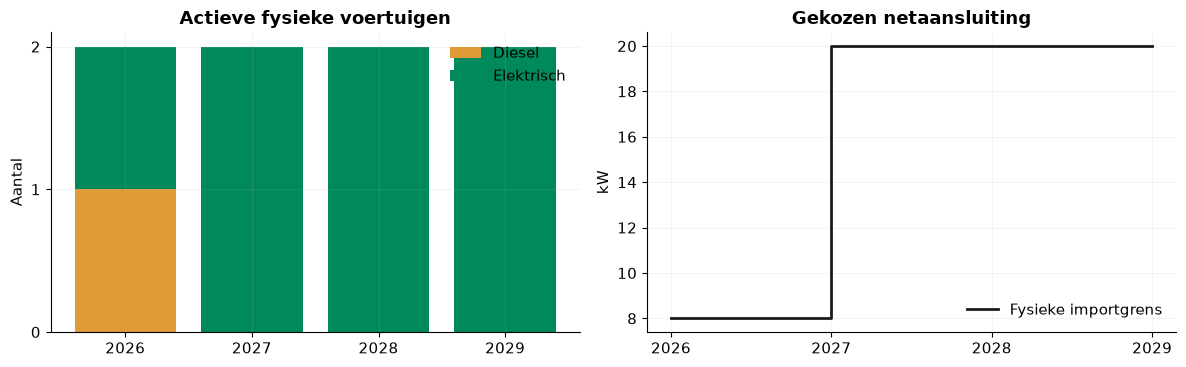

In [9]:
show_table(tables['fleet'])
plan=[]
value=lambda x: lin(x).value(result['values'])
for y,p in enumerate(model.d['periods']):
    site=model.d['sites'][0]
    chosen=next(g for g in site['grid_levels'] if value(model.levels['depot',y][g['id']])>.5)
    plan.append({'jaar':p['label'],'diesel':sum(value(model.z[a['id'],y]) for a in data['assets'] if a['powertrain']=='diesel'),
        'elektrisch':sum(value(model.z[a['id'],y]) for a in data['assets'] if a['powertrain']=='electric'),
        'netcontract kW':chosen['import_kw'],'laadkasten':sum(value(z) for (cid,yr),z in model.cabinets.items() if yr==y),
        'PV kW':sum(t['pv_kw']*value(u) for t,a,u in model.active_modules('depot','pv',y)),
        'opslag kWh':sum(t['energy_kwh']*value(u) for t,a,u in model.active_modules('depot','battery',y))})
show_table(plan)
fig,axes=plt.subplots(1,2,figsize=(12,3.8))
years=[r['jaar'] for r in plan]; diesel=[r['diesel'] for r in plan]; ev=[r['elektrisch'] for r in plan]
axes[0].bar(years,diesel,label='Diesel',color='#df9b38')
axes[0].bar(years,ev,bottom=diesel,label='Elektrisch',color='#008a5b')
axes[0].set(title='Actieve fysieke voertuigen',ylabel='Aantal',yticks=range(int(max(d+e for d,e in zip(diesel,ev)))+1)); axes[0].legend(frameon=False)
axes[1].step(years,[r['netcontract kW'] for r in plan],where='post',color='#191c1e',linewidth=2,label='Fysieke importgrens')
axes[1].set(title='Gekozen netaansluiting',ylabel='kW'); axes[1].legend(frameon=False)
fig.tight_layout(); plt.show()

### 4b · Diensten en dekking per scenario

Een volledig uitvoerbare oplossing dekt iedere ingevoerde dienst. Dat betekent
alleen dekking voor deze scenario's en deze bevestigde diensten. Een reserve van
nul is geen bewijs van uitvaldekking. Charter heeft capaciteit en een prijs.

In [10]:
show_table(tables['dispatch'])
coverage=[]
for sc in model.d['scenarios']:
    for y,op in enumerate(sc['operations']):
        own=sum(value(x) for key,x in model.assign.items() if key[:2]==(sc['id'],y))
        external=sum(value(x) for key,x in model.charter.items() if key[:2]==(sc['id'],y))
        days=len({j['day'] for j in op['duties']})
        coverage.append({'scenario':sc['id'],'jaar':model.d['periods'][y]['label'],'diensten in blok':len(op['duties']),
            'eigen dekking':round(own),'charter':round(external),'vlootdagen in blok':days,
            'CO₂ locatie + vervoer kg/jaar':round(value(model.carbon[sc['id'],y]))})
show_table(coverage)

base,2026,route_0,old_2,0
base,2026,route_1,ev_0_0_buy,0
base,2027,route_0,ev_0_0_buy,0
base,2027,route_1,ev_1_0_buy,0
base,2028,route_0,ev_0_0_buy,0
base,2028,route_1,ev_1_0_buy,0
base,2029,route_0,ev_1_0_buy,0
base,2029,route_1,ev_0_0_buy,0
cold_busy,2026,route_0,old_2,0
cold_busy,2026,route_1,ev_0_0_buy,0
cold_busy,2027,route_0,ev_1_0_buy,0


base,2026,2,2,0,1,18832
base,2027,2,2,0,1,10452
base,2028,2,2,0,1,10452
base,2029,2,2,0,1,10452
cold_busy,2026,2,2,0,1,19680
cold_busy,2027,2,2,0,1,11978
cold_busy,2028,2,2,0,1,11978
cold_busy,2029,2,2,0,1,11978


### 4c · Laden op de koude/drukke voorbeeldwerkdag

De bovenste grafiek is netzijdig; de onderste toont energie in de voertuigaccu.
De stippellijn in de bovenste grafiek is de fysieke importgrens. Het gebouw
blijft onderdeel van de balans. In deze demo is het geen echte jaarmeterreeks.

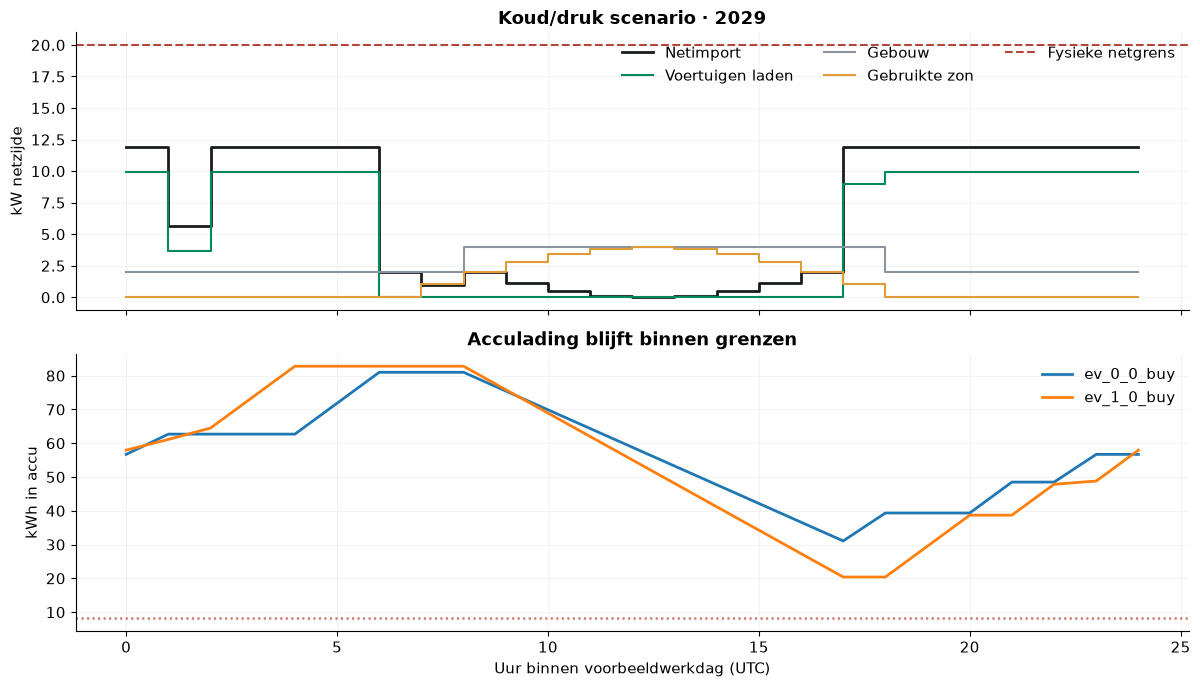

In [11]:
sid='cold_busy'; y=len(data['periods'])-1; T=len(model.d['periods'][y]['dt']); hours=np.arange(T)
op=model.d['scenarios'][1]['operations'][y]
imp=[value(model.v['import',sid,y,'depot',t]) for t in range(T)]
charge=[sum(value(v) for k,v in model.charging.items() if k[:2]==(sid,y) and k[-1]==t) for t in range(T)]
pv=[value(model.v['pv_used',sid,y,'depot',t]) for t in range(T)]
fig,axes=plt.subplots(2,1,figsize=(12,7),sharex=True)
edges=np.arange(T+1)
axes[0].step(edges,imp+[imp[-1]],where='post',label='Netimport',color='#191c1e',linewidth=2)
axes[0].step(edges,charge+[charge[-1]],where='post',label='Voertuigen laden',color='#008a5b')
building=op['sites']['depot']['building_kw']
axes[0].step(edges,building+[building[-1]],where='post',label='Gebouw',color='#8b949e')
axes[0].step(edges,pv+[pv[-1]],where='post',label='Gebruikte zon',color='#df9b38')
axes[0].axhline(plan[y]['netcontract kW'],ls='--',color='#b64539',label='Fysieke netgrens')
axes[0].set(title='Koud/druk scenario · '+plan[y]['jaar'],ylabel='kW netzijde'); axes[0].legend(ncol=3,frameon=False)
for a in model.d['assets']:
    if a['powertrain']=='electric' and value(model.z[a['id'],y])>.5:
        E=[value(e) for e in model.soc[sid,y,a['id']]]
        axes[1].plot(np.arange(T+1),E,label=a['id'],linewidth=2)
        axes[1].axhline(at(a['capacity_kwh'],y)*a['soc_min'],ls=':',color='#b64539',alpha=.5)
axes[1].set(xlabel='Uur binnen voorbeeldwerkdag (UTC)',ylabel='kWh in accu',title='Acculading blijft binnen grenzen')
axes[1].legend(frameon=False); fig.tight_layout(); plt.show()

### 4d · Kasstromen en financieringspiek

Negatieve bedragen zijn ontvangsten. Aankoop wordt op het aanschafmoment
geboekt, dus niet opnieuw als afschrijving in de economische NCW. Restwaarde
en resterende lease-/subsidieverplichtingen worden aan het einde verwerkt.
Het verschil tussen scenario's ontstaat uit toegestane operationele keuzes en kosten.

Voertuig-`fixed_cost`, `lease_cost`, `sale_value`, `contract_km` en
`normal_tax_shield` zijn **bedragen/volumes per beslisperiode**, geen automatisch
naar maand omgerekende jaarbedragen. Jaarlijkse infrastructuurfees worden met de
periodejaren vermenigvuldigd. Subsidiebetalingen zijn tijdstip/bedrag-paren.
Een refundable leasedeposit vereist een expliciete netto eindafrekening in de invoer.

base,0.8,91385.33,71930.0
cold_busy,0.2,95643.82,71930.0


vehicle_sale,-34528.85
vehicle_fixed,17572.43
vehicle_acquisition,89346.15
vehicle_terminal,-42820.56
charging_investment,4500.0
charging_maintenance,1295.62
charging_terminal,-2137.01
grid_fixed,3385.55
grid_investment,5769.23
energy_investment,5500.0
energy_maintenance,185.09


base,0.0,vehicle_sale,-19000.0
base,0.5,vehicle_fixed,2200.0
base,1.0,vehicle_sale,-16150.0
base,0.5,vehicle_fixed,2400.0
base,1.5,vehicle_fixed,2400.0
base,2.5,vehicle_fixed,2400.0
base,3.5,vehicle_fixed,2400.0
base,0.0,vehicle_acquisition,46000.0
base,4.0,vehicle_terminal,-25300.000000000004
base,1.5,vehicle_fixed,2400.0
base,2.5,vehicle_fixed,2400.0


18 van 35 rijen getoond; alle rijen blijven in de Python-uitvoer beschikbaar.


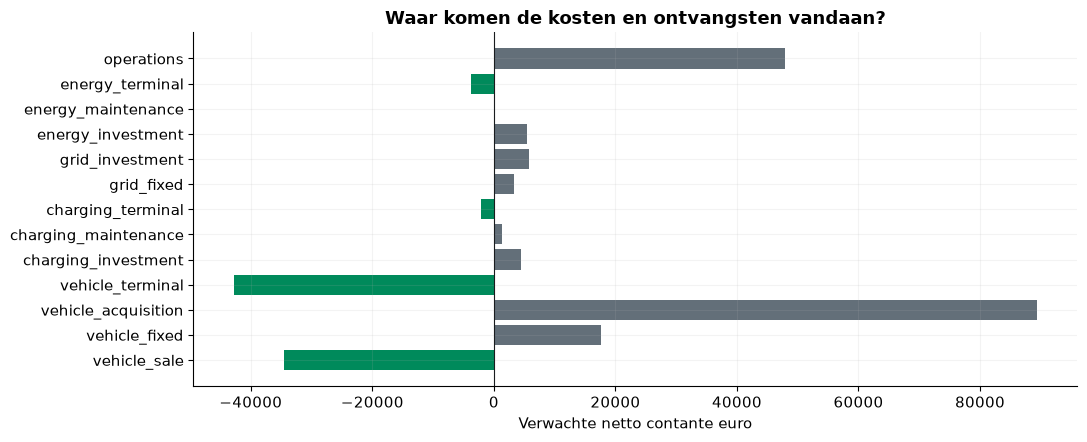

In [12]:
show_table([{'scenario':s['id'],'kans':s['probability'],'NCW €':round(result['scenario_npv'][s['id']],2),
    'kapitaalpiek €':round(result['capital_funding'][s['id']],2)} for s in data['scenarios']])
by_category=defaultdict(float)
for row in tables['cashflow']:
    prob=next(s['probability'] for s in data['scenarios'] if s['id']==row['scenario'])
    by_category[row['category']]+=prob*row['eur']/(1+data['discount_rate'])**row['time_years']
cost_rows=[{'categorie':k,'verwachte contante kosten €':round(v,2)} for k,v in by_category.items()]
show_table(cost_rows)
assert abs(sum(by_category.values())-result['expected_npv'])<.01
show_table([r for r in tables['cashflow'] if r['scenario']=='base'],limit=18)
cats=list(by_category); amounts=[by_category[c] for c in cats]
fig,ax=plt.subplots(figsize=(11,max(3,len(cats)*.35)))
ax.barh(cats,amounts,color=['#008a5b' if x<0 else '#636f79' for x in amounts]); ax.axvline(0,color='#191c1e',lw=.8)
ax.set(xlabel='Verwachte netto contante euro',title='Waar komen de kosten en ontvangsten vandaan?')
fig.tight_layout(); plt.show()

## 5 · Hetzelfde investeringsplan terugspelen

Hier staan de aanschaf-, actieve vloot-, infrastructuur-, subsidie- en
netbeslissingen vast. Alleen toegestane inzet en laden worden opnieuw gepland.
Een duurdere/koudere testcase mag zo niet stilzwijgend een andere vloot kopen.
Het basisscenario moet met hetzelfde investeringsplan dezelfde NCW geven binnen
de opgegeven solvergap. Bij een tijdslimiet tonen we het verschil.

In [13]:
replay_model,replay=fixed_plan_replay(data,result['decisions'],time_limit=30)
assert replay['feasible'], 'Het gekozen plan kan niet worden teruggespeeld.'
delta=replay['expected_npv']-result['expected_npv']
show_table([{'controle':'Vaste investeringen, opnieuw inzet/laden','uitvoerbaar':replay['feasible'],
    'NCW €':round(replay['expected_npv'],2),'verschil €':round(delta,4),'gap':replay['gap']}])
assert abs(delta)<=max(1.,result['gap']*abs(result['expected_npv'])+replay['gap']*abs(replay['expected_npv']))

"Vaste investeringen, opnieuw inzet/laden",True,92237.02,0.0,2.05096488302651e-15


### 5a · Huidige vloot als vergelijking

Voor deze fictieve vergelijking houden we investeringen op nul: bestaande
wagens mogen blijven of worden verkocht; er komt geen EV, laadkast, PV, opslag
of netverzwaring bij. Het **vrijwillige** laatstejaars-ZE-doel wordt voor deze
vergelijking uitgezet. Een wettelijke toegangseis op een dienst zou blijven gelden;
dan kan de huidige vloot terecht onuitvoerbaar zijn.

In [14]:
baseline=copy.deepcopy(data); baseline['minimum_ze_km_share']=[0.]*len(data['periods'])
freeze={}
for a in baseline['assets']:
    if not a['existing']: freeze[str(('buy',a['id']))]=0.
for c in baseline['cabinets']:
    for y in range(len(data['periods'])): freeze[str(('cabinet_build',c['id'],y))]=0.
for tech in baseline['energy_modules']:
    for a in tech['install_periods']: freeze[str(('module',tech['id'],a))]=0.
for site in baseline['sites']:
    for y in range(len(data['periods'])):
        for g in site['grid_levels']: freeze[str(('grid',site['id'],g['id'],y))]=float(g['id']==site['initial_grid'])
base_model=FleetModel(baseline,freeze); base_result=base_model.solve(30,.001)
if base_result['feasible']:
    base_model.verify_physics()
    show_table([{'plan':'Huidige vloot / geen nieuwe investering','NCW €':round(base_result['expected_npv'],2)},
        {'plan':'Gezamenlijk gekozen overstapplan','NCW €':round(result['expected_npv'],2)},
        {'plan':'Verschil in verwachte contante kosten','NCW €':round(base_result['expected_npv']-result['expected_npv'],2)}])
else: print('Huidige vloot niet uitvoerbaar:',base_result['status'])

Huidige vloot / geen nieuwe investering,105538.85
Gezamenlijk gekozen overstapplan,92237.02
Verschil in verwachte contante kosten,13301.83


### 5b · Gevoeligheden opnieuw optimaliseren

Voor snelle vergelijkingen nemen we hier twee beslisjaren en laten we PV/opslag
weg. Elke rij wordt **opnieuw** geoptimaliseerd. Dit zijn andere plannen, geen
bewijs dat het eerste plan bestand is tegen deze wijziging. Een vaste-plan-stressreplay
maak je met `fixed_plan_replay(gewijzigde_data, result['decisions'])`.

Een netinvestering waardeer je door de concrete hele variant opnieuw op te lossen,
met offerte, leverdatum en jaarlijkse tarieven. Een lokale LP-duaal na het vastzetten
van gehele beslissingen is geen algemene waarde van extra netcapaciteit.

In [15]:
quick=demo_data(2,False); quick['energy_modules']=[]
def dear_electricity(case):
    for sc in case['scenarios']:
        for op in sc['operations']:
            p=op['sites']['depot']; p['price_import']=[v*1.5 for v in p['price_import']]
def reserve_one(case): case['reserves']=[{'site':'depot','group':'delivery','count':1}]
def late_grid(case): case['sites'][0]['grid_levels'][1]['available_from']=len(case['periods'])
sensitivity=compare_cases(quick,[('Tweejaarsbasis',lambda d:None),('Stroom +50%',dear_electricity),
    ('Een gehele reservewagen',reserve_one),('Netverzwaring pas na horizon',late_grid)],time_limit=20)
show_table(sensitivity)

Tweejaarsbasis,True,True,47865.562996856796,3.0401638082314916e-16,0.5940751999996792
Stroom +50%,True,True,54487.19124791039,5.341407730913244e-16,0.5049837999999909
Een gehele reservewagen,True,True,66705.50374704252,2.1815164283220077e-16,0.25589450000006764
Netverzwaring pas na horizon,True,True,47865.562996856796,0.0,0.23755229999960648


## 6 · Automatische controles met bekende tegenvoorbeelden

Deze tests toetsen meer dan de voorbeeldoplossing: een exact berekenbare laadkost,
een tienjarige horizon, een onmogelijke opeenvolging zonder dagelijkse
accureset, reserve, koop/lease, verkoop op tijdstip nul, subsidievoorwaarden en
betaaltiming, grid-levertijd, stationuitval, fysiek omhangen, negatieve stroomprijzen,
belastingsegmenten, meerdere depots, ERE, bestaande opslag en een moedwillig
beschadigde oplossing. De matrixcontrole toetst daarnaast iedere solverrestrictie;
de fysieke nacontrole bouwt accu-, net- en kastbalansen afzonderlijk op.

Dit is softwareverificatie. Voor echte nauwkeurigheid zijn kalibratie, historie,
een representatieve praktijkdienst en een tweede inhoudelijke beoordelaar nodig.

In [16]:
"""Small, known-answer model tests; embedded and executed in the notebook too."""
import copy, math, tempfile, unittest
from pathlib import Path



def micro_case(demand=(0.,60.),depart=1,arrive=2,initial=.1):
    d=demo_data(1,False); T=len(demand)
    a=copy.deepcopy(next(a for a in d['assets'] if a['id']=='ev_0_0_buy'))
    a.update(id='ev',existing=True,exclusive_group=None,capacity_kwh=[100.],initial_soc=initial,
             terminal_soc=.1,ac_kw=100.,fixed_cost=[0.],sale_value=[0.],terminal_value=0.,maintenance_per_km=0.)
    d['assets']=[a]; d['energy_modules']=[]; d['minimum_ze_km_share']=[0.]
    d['sites'][0].update(grid_levels=[{'id':'current','import_kw':100.,'export_kw':100.,'annual_fixed':0.,'available_from':0}],
        grid_transitions=[{'from':'current','to':'current','cost':0.}],peak_kw_fee=0.,contract_kw_fee=0.)
    c=d['cabinets'][0]; c.update(existing=True,kw=100.,investment=0.,annual_cost=0.,terminal_value=0.)
    c['connectors']=[{'id':'plug','kind':'AC','kw':100.}]
    p=d['periods'][0]; start=datetime(2026,1,1,tzinfo=timezone.utc)
    p.update(mode='full_chronology',repeat=1.,duration_years=T/8760.,timestamps=[(start+timedelta(hours=t)).isoformat() for t in range(T+1)])
    op=d['scenarios'][0]['operations'][0]; j=op['duties'][0]
    j.update(depart=depart,arrive=arrive,latest_arrive=arrive,km=10.)
    j['variants']=[{'arrive':arrive,'work_hours':arrive-depart,'extra_cost':0.,'schedule_confirmed':True,'energy':{'ev_van':list(demand)},'road_windows':[]}]
    op['duties']=[j]; op['billing_bucket']=['one']*T; op['billing_multipliers']={'one':1}
    op['sites']['depot']={'building_kw':0.,'price_import':.1,'price_export':0.,'grid_co2':.3,'pv_per_kw':0.,'crew_capacity':2.}
    return d


def small_case(H=1):
    d=demo_data(H,False); d['energy_modules']=[]
    for g in d['sites'][0]['grid_levels']: g['import_kw']=100.
    d['sites'][0]['peak_kw_fee']=0.
    return d


def run_model(d,fixed=None):
    m=FleetModel(d,fixed); r=m.solve(15,.01)
    if r['feasible']: m.verify_physics()
    return m,r


class WholeFleetTests(unittest.TestCase):
    def test_known_chronological_energy(self):
        m,r=run_model(micro_case())
        self.assertTrue(r['feasible']); self.assertTrue(r['optimal'])
        self.assertAlmostEqual(r['expected_npv'],60/.92*.1/(1.04)**(1/8760),places=4)

    def test_no_daily_reset_between_periods(self):
        d=micro_case(); p=copy.deepcopy(d['periods'][0]); start=utc(p['timestamps'][-1])
        p['timestamps']=[(start+timedelta(hours=t)).isoformat() for t in range(3)]; p['label']='next'
        d['periods'].append(p)
        for a in d['assets']:
            a['capacity_kwh']=[100.,100.]; a['end_period']=2
            for k in ('fixed_cost','sale_value','normal_tax_shield','contract_km','lease_cost','exit_penalty'): a[k]=[at(a[k],0)]*2
        d['cabinets'][0]['end_period']=2
        op=copy.deepcopy(d['scenarios'][0]['operations'][0]); j=op['duties'][0]
        j['depart']=0; j['arrive']=1; j['latest_arrive']=1
        j['variants'][0].update(arrive=1,work_hours=1,energy={'ev_van':[60.,0.]})
        d['scenarios'][0]['operations'].append(op)
        d['annual_capex_limit']*=2; d['max_acquisitions']*=2; d['minimum_ze_km_share']=[0.,0.]
        m,r=run_model(d); self.assertFalse(r['feasible'])

    def test_all_purchase_and_lease_choices_are_decisions(self):
        d=small_case(); m,r=run_model(d)
        self.assertTrue(r['feasible'])
        buys={a['id']:m.buy[a['id']].value(r['values']) for a in d['assets'] if not a['existing']}
        self.assertAlmostEqual(sum(buys.values()),1)
        self.assertTrue(any('buy' in k and v>.5 for k,v in buys.items()))

    def test_ten_period_horizon(self):
        d=micro_case((0.,0.)); p=copy.deepcopy(d['periods'][0]); op=copy.deepcopy(d['scenarios'][0]['operations'][0])
        d['periods']=[]
        for y in range(10):
            q=copy.deepcopy(p); q.update(label=str(2026+y),duration_years=1.,mode='repeated_block',repeat=250.)
            q['timestamps']=[(datetime(2026+y,1,1,tzinfo=timezone.utc)+timedelta(hours=t)).isoformat() for t in range(3)]
            d['periods'].append(q)
        d['scenarios'][0]['operations']=[copy.deepcopy(op) for _ in range(10)]
        for a in d['assets']:
            a['end_period']=10
            for k,v in list(a.items()):
                if isinstance(v,list) and len(v)==1 and k not in ('ac_curve','dc_curve','incentives'): a[k]=v*10
        d['cabinets'][0]['end_period']=10
        for k in ('annual_capex_limit','max_acquisitions','minimum_ze_km_share'): d[k]*=10
        m,r=run_model(d); self.assertTrue(r['feasible']); self.assertEqual(len(m.d['periods']),10)
        self.assertEqual(m.d['horizon'],10.)

    def test_no_lease_mileage_on_owned_vehicle(self):
        m,r=run_model(micro_case())
        self.assertFalse(any(k[0]=='excess_km' for k in m.v))

    def test_operational_lease_tail_is_charged(self):
        d=small_case(); lease=next(a for a in d['assets'] if a['contract']=='operational_lease')
        fixed={str(('buy',lease['id'])):1.}
        m,r=run_model(d,fixed); self.assertTrue(r['feasible'])
        tail=lease['terminal_lease_liability']; self.assertGreater(tail,0)
        e=copy.deepcopy(d); next(a for a in e['assets'] if a['id']==lease['id'])['terminal_lease_liability']=0.
        n,s=run_model(e,fixed)
        self.assertAlmostEqual(r['expected_npv']-s['expected_npv'],tail/1.04,places=3)

    def test_initial_sale_is_in_cash_ledger(self):
        m,r=run_model(small_case()); self.assertTrue(r['feasible'])
        sales=[x for x in r['cashflows']['base'] if x['category']=='vehicle_sale' and x['time_years']==0]
        self.assertLess(sum(x['eur'] for x in sales),0)

    def test_explicit_reserve_keeps_third_vehicle(self):
        d=small_case(); d['reserves']=[{'site':'depot','group':'delivery','count':1}]
        m,r=run_model(d); self.assertTrue(r['feasible'])
        self.assertAlmostEqual(sum(z.value(r['values']) for (a,y),z in m.z.items()),3)

    def test_future_subsidy_cannot_pay_upfront(self):
        d=small_case(); a=next(a for a in d['assets'] if a['id']=='ev_0_0_buy')
        a['incentives']=[{'id':'verified_demo','kind':'grant','source':'synthetic test','confirmed':True,
             'hold_years':0.,'payments':[(.5,20000.)],'terminal_liability':0.}]
        d['capital_funding_limit']=1000.
        m,r=run_model(d,{str(('buy',a['id'])):1.}); self.assertFalse(r['feasible'])

    def test_incentive_holding_period(self):
        d=small_case(2); a=next(a for a in d['assets'] if a['id']=='ev_0_0_buy')
        a['incentives']=[{'id':'hold','kind':'grant','source':'synthetic test','confirmed':True,
             'hold_years':4.,'payments':[(0.,10000.)],'terminal_liability':5000.}]
        fixed={str(('buy',a['id'])):1.,str(('incentive',a['id'],'hold')):1.,str(('active',a['id'],1)):0.}
        m,r=run_model(d,fixed); self.assertFalse(r['feasible'])

    def test_tax_basis_and_vamil_validation(self):
        d=small_case(); a=next(a for a in d['assets'] if a['id']=='ev_0_0_buy')
        a['incentives']=[{'id':'tax','kind':'tax','source':'test','confirmed':True,'code':'D3116','year':2026,'vamil':.75}]
        with self.assertRaises(ValueError): validate(d)
        d['tax_basis']='after_tax'
        with self.assertRaises(ValueError): validate(d)

    def test_physical_grid_lead_time(self):
        d=small_case(); a=next(a for a in d['assets'] if a['id']=='ev_0_0_buy')
        d['sites'][0]['grid_levels'][0]['import_kw']=0.
        d['sites'][0]['grid_levels'][1]['available_from']=1
        self.assertFalse(run_model(d,{str(('buy',a['id'])):1.})[1]['feasible'])
        d['sites'][0]['grid_levels'][1]['available_from']=0
        self.assertTrue(run_model(d,{str(('buy',a['id'])):1.})[1]['feasible'])

    def test_public_charging_and_station_outage(self):
        d=micro_case((0,50,50,0),0,4,.7)
        d['road_stations']=[{'id':'road','kw':100.,'connectors':1,'price':.5,'co2':.3}]
        j=d['scenarios'][0]['operations'][0]['duties'][0]
        j['variants'][0]['road_windows']=[{'station':'road','start':1,'end':2,'kw':100.}]
        self.assertTrue(run_model(d)[1]['feasible'])
        d['scenarios'][0]['road_factors']={'road':0.}
        self.assertFalse(run_model(d)[1]['feasible'])

    def test_unused_road_stop_does_not_impose_80_percent(self):
        d=micro_case((0.,0.),0,2,.95)
        d['road_stations']=[{'id':'road','kw':100.,'connectors':1,'price':.5,'co2':.3}]
        d['scenarios'][0]['operations'][0]['duties'][0]['variants'][0]['road_windows']=[{'station':'road','start':0,'end':1,'kw':100.}]
        self.assertTrue(run_model(d)[1]['feasible'])

    def test_regen_can_be_curtailed_in_full_battery(self):
        d=micro_case((-10.,0.),0,2,1.)
        m,r=run_model(d); self.assertTrue(r['feasible'])
        self.assertGreater(m.v['regen_spill','base',0,'ev',0].value(r['values']),9.99)

    def test_switching_requires_staff(self):
        d=micro_case(); d['plug_policy']='switched'
        d['scenarios'][0]['operations'][0]['sites']['depot']['crew_capacity']=0.
        self.assertFalse(run_model(d)[1]['feasible'])
        d['scenarios'][0]['operations'][0]['sites']['depot']['crew_capacity']=1.
        self.assertTrue(run_model(d)[1]['feasible'])

    def test_pv_storage_and_negative_prices_are_physical(self):
        d=micro_case((0,0,50,0),2,3,.7)
        d['energy_modules']=demo_data(1,False)['energy_modules']
        profile=d['scenarios'][0]['operations'][0]['sites']['depot']
        profile.update(price_import=[-.1,.1,.4,.1],price_export=.2,pv_per_kw=[0,1,0,0])
        fixed={str(('module','pv',0)):1.,str(('module','battery',0)):1.}
        m,r=run_model(d,fixed); self.assertTrue(r['feasible'])
        for t in range(4):
            im=m.v['import','base',0,'depot',t].value(r['values']); ex=m.v['export','base',0,'depot',t].value(r['values'])
            self.assertLess(min(im,ex),1e-6)

    def test_energy_tax_uses_adjacent_segment(self):
        d=micro_case(); d['sites'][0]['energy_tax_breakpoints']=[(0.,0.),(10.,1.),(100.,5.5),(1000.,40.)]
        m,r=run_model(d); self.assertTrue(r['feasible'])
        volume=sum(m.v['import','base',0,'depot',t].value(r['values']) for t in range(2))
        points=d['sites'][0]['energy_tax_breakpoints']
        actual=sum(points[k][1]*m.v['tax_lambda','base',0,'depot',k].value(r['values']) for k in range(len(points)))
        expected=1+(volume-10)*.05
        self.assertAlmostEqual(actual,expected,places=5)

    def test_zero_weight_stress_has_no_free_charter(self):
        d=micro_case(); s=copy.deepcopy(d['scenarios'][0]); s.update(id='stress',probability=0.,charter_limit=1)
        d['scenarios'].append(s)
        with self.assertRaises(ValueError): validate(d)

    def test_cvar_and_fixed_plan_replay(self):
        d=micro_case(); s=copy.deepcopy(d['scenarios'][0]); s.update(id='expensive',probability=.5)
        s['operations'][0]['sites']['depot']['price_import']=1.
        d['scenarios'][0]['probability']=.5; d['scenarios'].append(s); d['risk_weight']=.5
        m,r=run_model(d); self.assertTrue(r['feasible']); self.assertGreaterEqual(r['objective']+1e-6,r['expected_npv'])
        n,q=fixed_plan_replay(d,r['decisions']); self.assertTrue(q['feasible'])

    def test_meter_gaps_and_customer_export(self):
        with tempfile.TemporaryDirectory() as tmp:
            p=Path(tmp)/'meter.csv'
            p.write_text('start,end,value,unit\n2026-01-01T00:00:00Z,2026-01-01T00:15:00Z,5,kWh\n',encoding='utf8')
            self.assertEqual(read_meter_csv(p)['intervals'][0]['kw'],20)
            p.write_text('start,end,value,unit\n2026-01-01T00:00:00,2026-01-01T00:15:00,5,kWh\n',encoding='utf8')
            with self.assertRaises(ValueError): read_meter_csv(p)
            m,r=run_model(micro_case()); m.d['data_kind']='customer'
            with self.assertRaises(ValueError): export_results(m,tmp)

    def test_mutated_solution_fails_independent_verifier(self):
        m,r=run_model(micro_case()); column=next(iter(m.soc['base',0,'ev'][1].c))
        r['values'][column]+=2
        with self.assertRaises(AssertionError): m.verify_physics()

    def test_segment_recuperation_and_stop_auxiliaries(self):
        downhill=segment_energy(3500,1000,10,-.1,regen_kw=2.,duration_hours=.1)
        self.assertAlmostEqual(downhill,-.2)
        self.assertGreater(segment_energy(3500,1000,10,.1),0)
        self.assertEqual(energy_from_activities([0.],[0.],[2.],.3,hvac_kw=1.,pto_hours=[1.],pto_kw=3.,
                         cooling_hours=[2.],cooling_kw=2.),[9.])

    def test_multiple_depots_keep_physical_location(self):
        d=micro_case((0.,10.,0.,10.),1,2,.7)
        other=copy.deepcopy(d['sites'][0]); other['id']='other'; d['sites'].append(other)
        op=d['scenarios'][0]['operations'][0]; op['sites']['other']=copy.deepcopy(op['sites']['depot'])
        first=op['duties'][0]; first['destination']='other'; first['day']='day_1'
        second=copy.deepcopy(first); second.update(id='return',day='day_2',origin='other',destination='depot',depart=3,arrive=4,latest_arrive=4)
        second['variants'][0].update(arrive=4,work_hours=1,energy={'ev_van':[0.,0.,0.,10.]})
        op['duties'].append(second)
        self.assertTrue(run_model(d)[1]['feasible'])
        second['origin']='depot'
        self.assertFalse(run_model(d)[1]['feasible'])

    def test_cabinet_grant_requires_new_equipment(self):
        d=micro_case((0.,0.)); d['infrastructure_grants']=[{'id':'project','confirmed':True,'source':'synthetic test',
             'period':0,'required_cabinets':['cab_0'],'payments':[(0.,1000.)]}]
        fixed={str(('infrastructure_grant','project')):1.}
        self.assertFalse(run_model(d,fixed)[1]['feasible'])
        d['cabinets'][0]['existing']=False
        self.assertTrue(run_model(d,fixed)[1]['feasible'])

    def test_duplicate_ports_and_bad_efficiency_rejected(self):
        d=micro_case(); d['cabinets'][0]['connectors']*=2
        with self.assertRaises(ValueError): validate(d)
        d=micro_case(); d['assets'][0]['eta_charge']=1.1
        with self.assertRaises(ValueError): validate(d)

    def test_asset_outage_needs_real_charter(self):
        d=micro_case((0.,0.)); sc=d['scenarios'][0]; sc['disabled_assets']=['ev']
        self.assertFalse(run_model(d)[1]['feasible'])
        sc['charter_limit']=1; j=sc['operations'][0]['duties'][0]; j.update(charter_allowed=True,charter_cost=500.)
        m,r=run_model(d); self.assertTrue(r['feasible']); self.assertGreater(r['expected_npv'],499.)

    def test_ere_cannot_exceed_net_import(self):
        d=micro_case(); d['sites'][0].update(ere_price=.01,ere_meter_factor=.92)
        m,r=run_model(d); self.assertTrue(r['feasible'])
        self.assertAlmostEqual(m.v['ere_kwh','base',0,'depot'].value(r['values']),60.,places=4)

    def test_existing_storage_preserves_terminal_energy(self):
        d=micro_case((0.,0.)); tech=copy.deepcopy(demo_data(1,False)['energy_modules'][1])
        tech.update(existing_units=1,existing_remaining_periods=3,existing_soc_kwh=10.,install_periods=[])
        d['energy_modules']=[tech]
        m,r=run_model(d); self.assertTrue(r['feasible'])
        E=m.storage['base',0,'depot','battery',-1]
        self.assertGreaterEqual(E[-1].value(r['values']),10.-1e-5)

    def test_charge_curve_is_limited_at_both_interval_boundaries(self):
        d=micro_case((0.,0.),initial=.5)
        d['assets'][0].update(ac_curve=[(1.,-1.)],terminal_soc=.8)
        self.assertFalse(run_model(d)[1]['feasible'])
        d['assets'][0]['terminal_soc']=.7
        self.assertTrue(run_model(d)[1]['feasible'])

In [17]:
suite=unittest.defaultTestLoader.loadTestsFromTestCase(WholeFleetTests)
test_result=unittest.TextTestRunner(verbosity=1).run(suite)
assert test_result.wasSuccessful(), 'Er is een modelcontrole mislukt.'
print(f'{test_result.testsRun} modeltests geslaagd.')

.

.

.

.

.

...

.

.

.

----------------------------------------------------------------------
Ran 30 tests in 2.225s

OK


30 modeltests geslaagd.


## 7 · Van fictieve invoer naar eigen data

`voorbeeld_invoer.json` naast dit notebook bevat de complete invoerstructuur.
De cel hieronder blijft standaard op de fictieve dataset. Vul lokaal een eigen
pad in en zet `data_kind` op `customer` voor klantdata.

| Bestand/onderdeel | Nodig voordat een echt plan verdedigbaar is |
|---|---|
| Voertuigen | Fysieke ID's, exacte uitvoering en bruikbare accu, payload/aslasten, kenmerken, AC/DC-acceptatie, SoH en gemeten begin-SoC. |
| Koop/lease | Bevestigde offerte/contractscope, start/einde, periodekosten, kilometerbundels, verkoopwaarde, beëindiging en netto eindverplichtingen. |
| Diensten | Werkelijke volgorde, tijdvensters, laden/stilstand, afstanden, belading, PTO/koeling, zones, bevestigde alternatieven en charterdekking. |
| Energie | Gevalideerde accu-kWh of diesel-liters per tijdstap/type/scenario. Segmentschatting is optioneel; een eenvoudige kWh/km-coëfficiënt is geen kalibratie. |
| Locaties | Bruto gebouwbelasting, bestaande EV/PV/BESS ontward, import/export, contract- en factuurtarieven, fysieke connectoren, kastvermogen en bereikbaarheid. Een thuislocatie moet als afzonderlijke site met echte capaciteit worden ingevoerd. |
| Tijd | Doorlopende tijdas, UTC-offsets en expliciete intervalduur; ontbrekende intervallen zijn geen nulbelasting. |
| Beleid/geld | Afgesproken gehele reserve, budgetten, discontovoet, scenario's, belastingbasis, bevestigde subsidievoorwaarden en uitbetaalmomenten. |

Een kalenderjaar kan 365 of 366 dagen hebben; de tijdas bepaalt de intervallen.
De engine gebruikt de aangeleverde financiële periodejaren, dus stem die af op
de gekozen dagtelconventie. Het demo-aantal van 250 werkdagen vermenigvuldigt ook
de gebouwlast; dat is hier een expliciete vereenvoudiging. Gebruik echte volledige
kalenderprofielen voor energiefacturen, kalenderpieken en PV-opbrengst.

Voor `full_chronology` is `repeat=1`, sluiten opeenvolgende perioden exact op
elkaar aan en is er geen dagelijkse reset. Verklein de tijdstap bij laadvensters
of pieken die binnen een uur veranderen. Miljoenen variabelen zijn mogelijk;
de rekentijd voor een echte grote vloot is nog niet gebenchmarkt.

**Bestaande energiemiddelen:** gebruik `existing_units`,
`existing_remaining_periods`, `existing_soc_kwh` en `existing_terminal_value`.
Bij een bestaande stationaire batterij is de gemeten beginenergie standaard ook
de minimale eindenergie. `terminal_soc_fraction` kan een andere afgesproken
eindvoorwaarde vastleggen. Zet bestaande PV in óf `existing_pv_kw` óf een bestaande
PV-module om dubbeltelling te voorkomen. `max_units` is de gelijktijdige fysieke
ruimte, `life_periods` telt beslisperioden; stem dit bij maandperioden expliciet af.

ERE-opbrengst, subsidietoekenning en belastingaftrek zijn **geen universele
kortingspercentages**. De invoer legt de gecontroleerde aanspraak, beperkingen,
ontvangstdatum en mogelijke terminale terugbetaling vast. Uitgesteld belastingvoordeel
vereist voldoende fiscale winst op dat moment. Operational lease bevat het
voordeel van de eigenaar al in de offerte; het wordt niet nogmaals bij de lessee geboekt.

In [18]:
CUSTOMER_JSON = None  # Bijvoorbeeld Path('/een/prive/map/bevestigde_casus.json')
if CUSTOMER_JSON is not None:
    customer_data=load_case(CUSTOMER_JSON)
    assert customer_data['data_kind']=='customer'
    customer_model=FleetModel(customer_data)
    customer_result=customer_model.solve(time_limit=300,gap=.005)
    print({k:customer_result.get(k) for k in ('status','feasible','gap','expected_npv')})
    if customer_result['feasible']:
        display(customer_model.verify_physics())
        show_table(customer_model.tables()['fleet'])
else:
    print('Demomodus: geen klantbestand geopend.')

Demomodus: geen klantbestand geopend.


### Meterexport controleren

De optionele CSV-lezer accepteert `start,end,value,unit` met `kWh` of `kW` en
expliciete UTC-offset. Hij weigert gaten, overlap en tijdstippen zonder tijdzone.
Hij bouwt geen ritten of contracten uit een meterexport. Koppel die afzonderlijk
en bevestig of je netto- of brutolast meet. Importeer eenheden aan de bron;
hernoemen van een kWh-kolom naar kW is geen conversie.

```csv
start,end,value,unit
2026-01-01T00:00:00+01:00,2026-01-01T00:15:00+01:00,5,kWh
2026-01-01T00:15:00+01:00,2026-01-01T00:30:00+01:00,4,kWh
```

### Export en reproduceerbaarheid

De demo kan lokaal als JSON en CSV worden opgeslagen. Klantuitvoer vraagt een
expliciet gekozen privélocatie en `allow_customer=True`. Wis ook notebookuitvoer
voordat je een notebook met klantdata deelt; celuitvoer kan gegevens bevatten.
Het ingevoerde JSON-bestand krijgt een SHA-256-hash voor traceerbaarheid.

In [19]:
SAVE_DEMO = False
if SAVE_DEMO:
    out=export_results(model,Path('demo_resultaten'))
    Path(out/'invoer.json').write_text(json.dumps(data,indent=2,ensure_ascii=False),encoding='utf8')
    print('Demo opgeslagen in:',out.resolve())
else:
    print('Resultaten staan in model, result en tables; er zijn geen exportbestanden aangemaakt.')

Resultaten staan in model, result en tables; er zijn geen exportbestanden aangemaakt.


## Wat deze uitvoering aantoont

Het gezamenlijke MILP kan in dit notebook worden gebouwd, opgelost, teruggespeeld
en gecontroleerd. De volledige rekenkern en tegenvoorbeelden staan in het bestand.
Een uitkomst is een optimum binnen ingevoerde kandidaten, tijdstappen, scenario's
en eventuele solvergap. Een ontbrekend voertuigslot of een verkeerd verbruiksprofiel
wordt niet door AI of de solver gerepareerd.

De demo is geen praktijkvalidatie. Begin een klantpilot met een beperkte,
bevestigde scope; vergelijk voorspelling en meting en rapporteer onbekende data,
charterafhankelijkheid en niet gedekte scenario's expliciet. De website voert
dit notebook nog niet als online vlootoptimizer uit.

Zie ook [de modelbeschrijving](03-model.md), [data-eisen](02-data.md) en
[correcties en acceptatie](08-correcties-en-acceptatie.md).